# Pipeline CNN completo: clasificación de platos típicos peruanos (PeruFoodNet)

**Universidad Nacional del Centro del Perú**

**Facultad de Ingeniería de Sistemas**

**Curso:** Ingeniería del Conocimiento (ISO56B)

**Docente:** Msc. Jaime Antonio Huaytalla Pariona

**Semestre:** 2026-II
**Fecha:** 08-11-2026

**Integrantes:**

| Nombre | Código |
|---|---|
| Gutierrez Vega Bill Toño | 2012100229F |
| Quispealaya Vera Elias Carlos | 2024200203H |
| Lopez Granados Karito Dali Yoselyn | 2024200191I |
| Paredes Huarcaya Jose Michael | 2024101399J |

---
**Estructura del notebook (pipeline de 12 fases):**
1. Definición del problema
2. Selección y validación del dataset
3. EDA de imágenes
4. Preprocesamiento
5. Arquitecturas CNN
6. Entrenamiento
7. Evaluación rigurosa
8. Análisis de errores
9. Comparación sistemática de modelos
10. Versionado del proyecto
11. Logging y registro de experimentos
12. Documentación técnica y despliegue

# Fase 1: Definición del problema

Antes de escribir código se responden cinco preguntas que condicionan todas las decisiones posteriores: la capa de salida, la función de pérdida, las métricas, el tamaño del modelo y el criterio para saber si el modelo realmente sirve.

## 1.1 ¿Qué problema resuelvo?

Dada una fotografía de un plato de comida, el modelo debe identificar a cuál de **40 platos típicos peruanos** corresponde (por ejemplo, Ceviche, Anticuchos, Lomo Saltado, Ají de Gallina).

**Contexto y utilidad:** la gastronomía peruana atrae turistas de todo el mundo, pero algunos platos contienen ingredientes que pueden causar reacciones alérgicas. Reconocer el plato a partir de una foto permite asociarlo a su lista de ingredientes y, a futuro, avisar de posibles alérgenos mediante una aplicación o un chatbot. Esa es justamente la motivación de los autores del dataset.

## 1.2 ¿Es clasificación binaria o multiclase?

**Clasificación multiclase:** cada imagen pertenece a **una sola** de las 40 categorías.

Esto define el diseño del modelo:
- **Capa de salida:** `Dense(40, activation="softmax")`, una neurona por plato; `softmax` convierte las 40 salidas en probabilidades que suman 1.
- **Función de pérdida:** entropía cruzada categórica (la variante exacta, con etiquetas enteras o con *label smoothing*, se fija en la Fase 6).

## 1.3 ¿Cuál es la métrica de éxito?

| Métrica | Para qué se usa |
|---|---|
| **Macro F1-score** (principal) | Promedia el F1 de las 40 clases por igual, de modo que ningún plato queda oculto detrás de un promedio global. |
| Accuracy global | Referencia general e intuitiva. |
| Accuracy top-3 | Útil con 40 clases parecidas: indica si el plato correcto está entre las 3 predicciones más probables. |
| AUC macro (One-vs-Rest) | Mide qué tan bien se separa cada plato del resto, sin depender de un umbral. |
| Matriz de confusión y reporte por clase | Identifican qué platos se confunden entre sí (Fases 7 y 8). |

**Nota:** el dataset está perfectamente balanceado (100 imágenes por plato), por lo que accuracy y Macro F1 serán parecidos; aun así se reporta Macro F1 como métrica principal por ser la que exige el pipeline profesional.

## 1.4 ¿Cuáles son las restricciones?


| Restricción | Valor |
|---|---|
| **Tamaño del modelo** | Menor a 50 MB, para poder exportarlo a TFLite y usarlo en un dispositivo móvil. |
| **Tiempo de inferencia** | Una predicción por imagen en menos de 1 segundo en CPU. |
| **Hardware y entorno** | GPU local NVIDIA GeForce RTX 5060 Laptop (8 GB), con Keras 3 y PyTorch como backend. |
| **Datos** | Pocas imágenes por clase (100), por lo que se necesitará *data augmentation* (Fase 4). |
| **Despliegue** | Modelo `.keras`, API REST de predicción con Django REST Framework y, si es viable, exportación a TFLite/ONNX para móvil (Fase 12). |

## 1.5 ¿Cuál es la línea base (baseline)?

Un clasificador trivial que adivina al azar entre 40 clases acierta con probabilidad **1/40 = 2.5%**. Cualquier modelo útil debe superar con claridad ese valor. Más adelante la CNN base (Fase 5) servirá como línea base de modelo para comparar las arquitecturas mejoradas.

## 1.6 Ficha resumen del problema (*Case Study Card*)

| Elemento | Definición |
|---|---|
| **Tipo** | Clasificación multiclase (40 categorías) |
| **Dataset** | PeruFoodNet (4,000 imágenes, 100 por clase) |
| **Fuente** | Mendeley Data, DOI: 10.17632/hxhbbm497d.3 |
| **Referencia** | Arzola Gutierrez, Canchari Muñoz y Escobedo Cárdenas (2025), *Data in Brief*, vol. 60. DOI: 10.1016/j.dib.2025.111604 |
| **Métrica principal** | Macro F1-score |
| **Baseline** | 2.5% de accuracy (azar: 1/40) |
| **Restricciones** | Modelo < 50 MB, inferencia < 1 s en CPU, GPU de 8 GB, backend PyTorch |

# Fase 2: Selección y validación del dataset

## 2.1 Criterios mínimos de aceptación

Antes de aceptar un dataset se comprueba que cumpla los criterios mínimos de la guía del curso. Los repositorios recomendados son Kaggle, TensorFlow Datasets, Hugging Face y Roboflow Universe; aquí se usó **Mendeley Data**, que aloja datasets publicados junto con artículos científicos.

| Criterio | Requisito | PeruFoodNet | Cumple |
|---|---|---|---|
| **Volumen** | ≥ 1,000 imágenes en total | 4,000 imágenes | Sí |
| **Complejidad** | ≥ 3 clases diferentes | 40 platos | Sí |
| **Viabilidad** | Contexto claro y aplicabilidad al mundo real | Reconocimiento de platos típicos e inferencia de alérgenos | Sí |
| **Exclusiones** | No usar MNIST ni Fashion-MNIST | No es ninguno de los dos | Sí |

Los números de volumen y clases se **verifican con código** en la sección 2.6, en lugar de confiar solo en la descripción del autor.

## 2.2 Dataset seleccionado

**PeruFoodNet** es un dataset de 4,000 imágenes de 40 platos típicos peruanos, con 100 imágenes por plato, tomadas desde distintos ángulos, entornos e iluminaciones. Fue creado por estudiantes de Ingeniería de Sistemas de la Universidad de Lima.

- **Fuente:** https://data.mendeley.com/datasets/hxhbbm497d/3
- **DOI:** 10.17632/hxhbbm497d.3
- **Artículo:** Arzola Gutierrez, Canchari Muñoz y Escobedo Cárdenas (2025), *Data in Brief*, vol. 60. DOI: 10.1016/j.dib.2025.111604

**Justificación de la elección:** es un problema de clasificación de imágenes reales con contexto local, cumple todos los criterios mínimos y tiene una aplicación concreta (reconocer el plato para asociarlo a sus ingredientes y posibles alérgenos). Con 40 clases, hay platos visualmente parecidos, lo que permite un análisis de errores significativo en las Fases 8 y 9. Su limitación es el tamaño: 100 imágenes por clase es poco para una CNN entrenada desde cero, por lo que se usará *data augmentation* (Fase 4).

## 2.3 Descarga y estructura de carpetas

El dataset se descargó manualmente desde la página de Mendeley Data (botón de descarga) y se descomprimió en la carpeta `Dataset_PeruFoodNet/` dentro de la carpeta del proyecto. Hay una carpeta por plato; el nombre de la carpeta es la **clase** de cada imagen.

```
proyecto_comida/
├── Dataset_PeruFoodNet/
│   ├── (carpeta de un plato)/   ← 100 imágenes
│   └── ... (40 carpetas)
└── comida_peru.ipynb
```

## 2.4 Configuración del entorno

`KERAS_BACKEND` indica qué motor hace los cálculos de la red (aquí PyTorch, porque soporta la GPU RTX 5060); debe definirse **antes** de importar Keras. `keras.utils.set_random_seed` fija la semilla de Python, NumPy y del backend para que los resultados sean reproducibles. `torch.cuda.is_available()` confirma que la GPU está activa.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # debe ir ANTES de importar keras

import keras, torch

SEED = 42
keras.utils.set_random_seed(SEED)

print("Keras:", keras.__version__, "| backend:", keras.backend.backend())
print("GPU disponible:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ninguna")

Keras: 3.15.1 | backend: torch
GPU disponible: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 2.5 Listar las imágenes y sus etiquetas

Se recorre `DATA_DIR` con `os.walk` (visita todas las subcarpetas). El nombre de la carpeta que contiene cada imagen es su **clase**. Se arma una tabla (`DataFrame`) con la ruta y la clase de cada imagen.

- `Path` (de `pathlib`) maneja rutas de archivos de forma independiente del sistema operativo.
- `PROYECTO` es la carpeta desde la que se abre el notebook (`Path.cwd()`), es decir, `proyecto_comida/`.
- `EXT` es el conjunto de extensiones que se consideran imágenes; los demás archivos se cuentan en `otros` y se ignoran.
- `CLASES` es la lista ordenada de platos y `clase_a_id` asigna a cada uno un número entero (0 a 39), que se usará más adelante como etiqueta.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd

PROYECTO = Path.cwd()
DATA_DIR = PROYECTO / "data" / "raw" / "Dataset_PeruFoodNet"
EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"No se encontró el dataset en: {DATA_DIR}\n"
        "Descárgalo desde Mendeley Data y colócalo en la carpeta Dataset_PeruFoodNet."
    )
print("Proyecto:", PROYECTO)

registros, otros = [], 0
for carpeta, _, archivos in os.walk(DATA_DIR):
    for a in archivos:
        if Path(a).suffix.lower() in EXT:
            registros.append((str(Path(carpeta) / a), Path(carpeta).name))
        else:
            otros += 1

df_total = pd.DataFrame(registros, columns=["ruta", "clase"])
CLASES = sorted(df_total["clase"].unique())
clase_a_id = {c: i for i, c in enumerate(CLASES)}

print("Imágenes encontradas:", len(df_total), "| Clases:", len(CLASES))
print("Archivos que no son imagen (ignorados):", otros)
muestras_por_clase = {
    clase: (
        df_total.loc[df_total["clase"].eq(clase), "ruta"]
        .map(lambda ruta: Path(ruta).name)
        .sort_values()
        .head(10)
        .reset_index(drop=True)
    )
    for clase in CLASES
}
tabla_muestras = pd.DataFrame(muestras_por_clase)
display(tabla_muestras)

Proyecto: d:\ingeniería_de_sistemas\semestre_5\ingenieria_del_conocimiento\semana_11\proyecto_comida
Imágenes encontradas: 4000 | Clases: 40
Archivos que no son imagen (ignorados): 0


,Aguadito,Aji de Gallina,Anticuchos,Arroz Chaufa,Arroz Tapado,Arroz con Mariscos,Arroz con Pollo,Bisteck a lo Pobre,Caldo de Gallina,Carapulcra,...,Pollo a la Brasa,Pollo al horno con puré,Pulpo al Olivo,Rocoto Relleno,Sopa a la Minuta,Tacu Tacu,Tallarin Saltado,Tallarines Rojos,Tallarines Verdes,Tamales
0,01_Aguadito.jpg,01_Aji_de_Gallina.jpg,01_Anticuchos.jpg,01_Arroz_Chaufa.jpg,01_Arroz_Tapado.jpg,01_Arroz_Mariscos.jpg,01_Arroz_con_Pollo.jpg,01_Bisteck_A_Lo_Pobre.jpg,01_Caldo_de_Gallina.jpg,01_Carapulcra.jpg,...,01_Pollo_A_La_Brasa.jpg,01_Pollo_Horno_Pure.jpg,01_Pulpo_Olivo.jpg,01_Rocoto_Relleno.jpg,01_Sopa_Minuta.jpg,01_Tacu_Tacu.jpg,01_Tallarin_Saltado.jpg,01_Tallarines_Rojos.jpg,01_Tallarines_Verdes.jpg,01_Tamales.jpg
1,02_Aguadito.jpg,02_Aji_de_Gallina.jpg,02_Anticuchos.jpg,02_Arroz_Chaufa.jpg,02_Arroz_Tapado.jpg,02_Arroz_Mariscos.jpg,02_Arroz_con_Pollo.jpg,02_Bisteck_A_Lo_Pobre.jpg,02_Caldo_de_Gallina.jpg,02_Carapulcra.jpg,...,02_Pollo_A_La_Brasa.jpg,02_Pollo_Horno_Pure.jpg,02_Pulpo_Olivo.jpg,02_Rocoto_Relleno.jpg,02_Sopa_Minuta.jpg,02_Tacu_Tacu.jpg,02_Tallarin_Saltado.jpg,02_Tallarines_Rojos.jpg,02_Tallarines_Verdes.jpg,02_Tamales.jpg
2,03_Aguadito.jpg,03_Aji_de_Gallina.jpg,03_Anticuchos.jpg,03_Arroz_Chaufa.jpg,03_Arroz_Tapado.jpg,03_Arroz_Mariscos.jpg,03_Arroz_con_Pollo.jpg,03_Bisteck_A_Lo_Pobre.jpg,03_Caldo_de_Gallina.jpg,03_Carapulcra.jpg,...,03_Pollo_A_La_Brasa.jpg,03_Pollo_Horno_Pure.jpg,03_Pulpo_Olivo.jpg,03_Rocoto_Relleno.jpg,03_Sopa_Minuta.jpg,03_Tacu_Tacu.jpg,03_Tallarin_Saltado.jpg,03_Tallarines_Rojos.jpg,03_Tallarines_Verdes.jpg,03_Tamales.jpg
3,04_Aguadito.jpg,04_Aji_de_Gallina.jpg,04_Anticuchos.jpg,04_Arroz_Chaufa.jpg,04_Arroz_Tapado.jpg,04_Arroz_Mariscos.jpg,04_Arroz_con_Pollo.jpg,04_Bisteck_A_Lo_Pobre.jpg,04_Caldo_de_Gallina.jpg,04_Carapulcra.jpg,...,04_Pollo_A_La_Brasa.jpg,04_Pollo_Horno_Pure.jpg,04_Pulpo_Olivo.jpg,04_Rocoto_Relleno.jpg,04_Sopa_Minuta.jpg,04_Tacu_Tacu.jpg,04_Tallarin_Saltado.jpg,04_Tallarines_Rojos.jpg,04_Tallarines_Verdes.jpg,04_Tamales.jpg
4,05_Aguadito.jpg,05_Aji_de_Gallina.jpg,05_Anticuchos.jpg,05_Arroz_Chaufa.jpg,05_Arroz_Tapado.jpg,05_Arroz_Mariscos.jpg,05_Arroz_con_Pollo.jpg,05_Bisteck_A_Lo_Pobre.jpg,05_Caldo_de_Gallina.jpg,05_Carapulcra.jpg,...,05_Pollo_A_La_Brasa.jpg,05_Pollo_Horno_Pure.jpg,05_Pulpo_Olivo.jpg,05_Rocoto_Relleno.jpg,05_Sopa_Minuta.jpg,05_Tacu_Tacu.jpg,05_Tallarin_Saltado.jpg,05_Tallarines_Rojos.jpg,05_Tallarines_Verdes.jpg,05_Tamales.jpg
5,06_Aguadito.jpg,06_Aji_de_Gallina.jpg,06_Anticuchos.jpg,06_Arroz_Chaufa.jpg,06_Arroz_Tapado.jpg,06_Arroz_Mariscos.jpg,06_Arroz_con_Pollo.jpg,06_Bisteck_A_Lo_Pobre.jpg,06_Caldo_de_Gallina.jpg,06_Carapulcra.jpg,...,06_Pollo_A_La_Brasa.jpg,06_Pollo_Horno_Pure.jpg,06_Pulpo_Olivo.jpg,06_Rocoto_Relleno.jpg,06_Sopa_Minuta.jpg,06_Tacu_Tacu.jpg,06_Tallarin_Saltado.jpg,06_Tallarines_Rojos.jpg,06_Tallarines_Verdes.jpg,06_Tamales.jpg
6,07_Aguadito.jpg,07_Aji_de_Gallina.jpg,07_Anticuchos.jpg,07_Arroz_Chaufa.jpg,07_Arroz_Tapado.jpg,07_Arroz_Mariscos.jpg,07_Arroz_con_Pollo.jpg,07_Bisteck_A_Lo_Pobre.jpg,07_Caldo_de_Gallina.jpg,07_Carapulcra.jpg,...,07_Pollo_A_La_Brasa.jpg,07_Pollo_Horno_Pure.jpg,07_Pulpo_Olivo.jpg,07_Rocoto_Relleno.jpg,07_Sopa_Minuta.jpg,07_Tacu_Tacu.jpg,07_Tallarin_Saltado.jpg,07_Tallarines_Rojos.jpg,07_Tallarines_Verdes.jpg,07_Tamales.jpg
7,08_Aguadito.jpg,08_Aji_de_Gallina.jpg,08_Anticuchos.jpg,08_Arroz_Chaufa.jpg,08_Arroz_Tapado.jpg,08_Arroz_Mariscos.jpg,08_Arroz_con_Pollo.jpg,08_Bisteck_A_Lo_Pobre.jpg,08_Caldo_de_Gallina.jpg,08_Carapulcra.jpg,...,08_Pollo_A_La_Brasa.jpg,08_Pollo_Horno_Pure.jpg,08_Pulpo_Olivo.jpg,08_Rocoto_Relleno.jpg,08_Sopa_Minuta.jpg,08_Tacu_Tacu.jpg,08_Tallarin_Saltado.jpg,08_Tallarines_Rojos.jpg,08_Tallarines_Verdes.jpg,08_Tamales.jpg
8,09_Aguadito.jpg,09_Aji_de_Gallina.jpg,09_Anticuchos.jpg,09_Arroz_Chaufa.jpg,09_Arroz_Tapado.jpg,09_Arroz_Mariscos.jpg,09_Arroz_con_Pollo.jpg,09_Bisteck_A_Lo_Pobre.jpg,09_Caldo_de_Gallina.jpg,09_Carapulcra.jpg,...,09_Pollo_A_La_Brasa.jpg,09_Pollo_Horno_Pure.jpg,09_Pulp

## 2.6 Validación del dataset

Se comprueba con código que el dataset descargado coincide con lo que describe el autor: 4,000 imágenes, 40 clases y 100 imágenes por clase. `value_counts` cuenta las apariciones de cada clase y `reindex` las ordena según `CLASES`. Si alguna comprobación falla, hay que revisar la descarga o la estructura de carpetas antes de continuar.

In [3]:
conteo = df_total["clase"].value_counts().reindex(CLASES)

verificaciones = {
    "Volumen >= 1,000 imágenes": len(df_total) >= 1000,
    "Complejidad >= 3 clases": len(CLASES) >= 3,
    "Total esperado: 4,000 imágenes": len(df_total) == 4000,
    "Clases esperadas: 40": len(CLASES) == 40,
    "100 imágenes por clase": bool((conteo == 100).all()),
}
for criterio, ok in verificaciones.items():
    print(f"[{'OK' if ok else 'FALLA'}] {criterio}")

print("\nImágenes por clase:")
print(conteo.to_string())

anomalas = conteo[conteo != 100]
if len(anomalas):
    print("\nClases con un número distinto de 100 imágenes:")
    print(anomalas.to_string())

[OK] Volumen >= 1,000 imágenes
[OK] Complejidad >= 3 clases
[OK] Total esperado: 4,000 imágenes
[OK] Clases esperadas: 40
[OK] 100 imágenes por clase

Imágenes por clase:
clase
Aguadito                   100
Aji de Gallina             100
Anticuchos                 100
Arroz Chaufa               100
Arroz Tapado               100
Arroz con Mariscos         100
Arroz con Pollo            100
Bisteck a lo Pobre         100
Caldo de Gallina           100
Carapulcra                 100
Cau Cau                    100
Causa Limeña               100
Ceviche                    100
Chanfainita                100
Chicharron de Mariscos     100
Chicharron de cerdo        100
Choclo con Queso           100
Choritos a la Chalaca      100
Escabeche                  100
Frejoles                   100
Humitas                    100
Lentejitas                 100
Locro                      100
Lomo Saltado               100
Ocopa                      100
Olluquito                  100
Papa Rellena     

# Fase 3: EDA para imágenes

El análisis exploratorio (EDA) revisa el dataset **antes** de entrenar, para descubrir problemas que afectarían al modelo: clases desbalanceadas, imágenes dañadas o repetidas, tamaños muy distintos, fotos muy oscuras o desenfocadas. Lo que se encuentre aquí guía las decisiones de preprocesamiento de la Fase 4.

## 3.1 Distribución de clases

Se cuenta cuántas imágenes tiene cada plato y se calcula el **ratio de desbalance** (clase más grande dividida entre la más pequeña). Un dataset muy desbalanceado puede llevar al modelo a favorecer a las clases mayoritarias y a producir una accuracy global engañosa.

d:\ingeniería_de_sistemas\semestre_5\ingenieria_del_conocimiento\semana_11\proyecto_comida\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mínimo: 100 (Aguadito) | Máximo: 100 (Aguadito)
Ratio de desbalance: 1.0:1


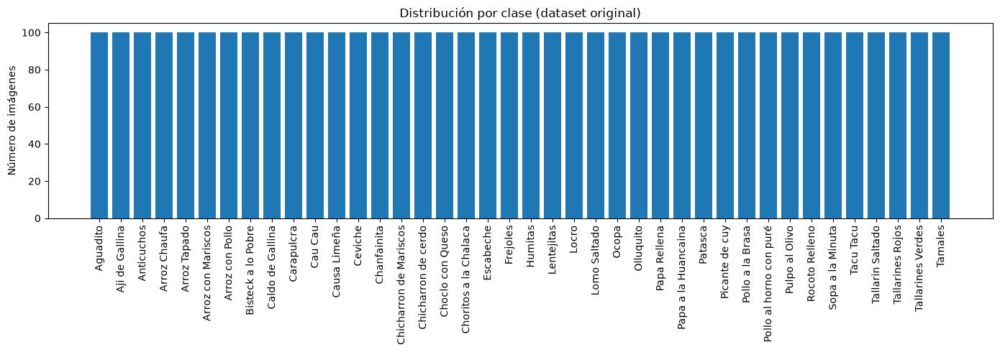

In [4]:
import time, hashlib
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

conteo = df_total["clase"].value_counts().reindex(CLASES)
ratio = conteo.max() / conteo.min()
print(f"Mínimo: {conteo.min()} ({conteo.idxmin()}) | Máximo: {conteo.max()} ({conteo.idxmax()})")
print(f"Ratio de desbalance: {ratio:.1f}:1")

plt.figure(figsize=(14, 5))
plt.bar(CLASES, conteo.values)
plt.xticks(rotation=90)
plt.ylabel("Número de imágenes")
plt.title("Distribución por clase (dataset original)")
plt.tight_layout()
plt.show()

## 3.2 Análisis de todas las imágenes (una sola pasada)

Para no abrir cada imagen varias veces, la función `analizar` la abre una sola vez y extrae todo lo que necesitan las secciones siguientes. `ThreadPoolExecutor` procesa varias imágenes en paralelo y `tqdm` muestra una barra de progreso.

| Dato | Para qué sirve |
|---|---|
| `h_ex` (hash MD5 del archivo) | Detectar copias **exactas** (mismos bytes). |
| `formato`, `modo`, `canales`, `ancho`, `alto`, `tam_kb` | Propiedades: dimensiones, canales de color y peso del archivo. |
| `im.verify()` y lectura completa | Detectar archivos **corruptos o truncados**. |
| `h_ap` (hash aproximado) | Detectar copias casi idénticas: la imagen se reduce a 16×16 en grises y cada píxel se marca como más claro o más oscuro que el promedio (256 bits). |
| `brillo`, `contraste`, `nitidez` | Detectar ruido visual: media de grises, desviación estándar y varianza del filtro Laplaciano (a menor valor, más desenfocada). Se calculan sobre una versión reducida de 64×64, así que sirven para **comparar** imágenes entre sí. |

Si una imagen falla, se guarda `ok = False` y el mensaje de error, en lugar de detener el análisis.

In [5]:
def analizar(ruta):
    r = {"ok": True, "error": ""}
    try:
        with open(ruta, "rb") as f:
            r["h_ex"] = hashlib.md5(f.read()).hexdigest()
        r["tam_kb"] = os.path.getsize(ruta) / 1024

        with Image.open(ruta) as im:
            r["formato"] = im.format
            r["modo"] = im.mode
            r["canales"] = len(im.getbands())
            r["ancho"], r["alto"] = im.size
            im.verify()                      # detecta archivos dañados

        with Image.open(ruta) as im:         # verify() obliga a reabrir
            im.draft("RGB", (256, 256))      # acelera la lectura de JPEG
            g = np.asarray(im.convert("L").resize((64, 64), Image.Resampling.BILINEAR),
                           dtype=np.float32)

        r["brillo"] = float(g.mean())
        r["contraste"] = float(g.std())
        lap = 4 * g[1:-1, 1:-1] - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]
        r["nitidez"] = float(lap.var())

        p = g.reshape(16, 4, 16, 4).mean(axis=(1, 3))          # reducción a 16x16
        r["h_ap"] = np.packbits((p > p.mean()).ravel()).tobytes().hex()
    except Exception as e:
        r["ok"] = False
        r["error"] = f"{type(e).__name__}: {e}"
    return r

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as ex:
    res = list(tqdm(ex.map(analizar, df_total["ruta"]), total=len(df_total), desc="Analizando"))

df_eda = pd.concat([df_total.reset_index(drop=True), pd.DataFrame(res)], axis=1)
print(f"Análisis terminado en {time.time() - t0:.0f} s | imágenes analizadas: {len(df_eda)}")

Analizando: 100%|██████████| 4000/4000 [00:08<00:00, 486.57it/s]

Análisis terminado en 8 s | imágenes analizadas: 4000


## 3.3 Imágenes corruptas

Se listan las imágenes que no pudieron abrirse o leerse por completo (`Image.open().verify()` más una lectura completa del archivo). Estas imágenes no pueden usarse para entrenar y se descartan; `df_ok` conserva solo las imágenes sanas.

In [7]:
corruptas = df_eda[~df_eda["ok"]]
print("Imágenes corruptas o ilegibles:", len(corruptas))
if len(corruptas):
    print(corruptas[["ruta", "clase", "error"]].to_string(index=False))

df_ok = df_eda[df_eda["ok"]].copy()
print("Imágenes sanas:", len(df_ok))

Imágenes corruptas o ilegibles: 0
Imágenes sanas: 4000


## 3.4 Dimensiones, canales y formatos

Se resumen las propiedades de las imágenes **originales**:

- **Ancho y alto:** determinan a qué resolución se reducirán las imágenes (Fase 4). Reducir demasiado pierde detalle; reducir poco encarece el entrenamiento.
- **Relación de aspecto** (ancho / alto): si varía mucho, al redimensionar a un cuadrado las imágenes se deforman.
- **Canales:** una CNN con entrada RGB necesita 3 canales; las imágenes en gris (1 canal) o con transparencia (4 canales) deben convertirse.
- **Formato y peso:** informativos; el peso ayuda a detectar imágenes demasiado pequeñas o comprimidas.

Los tamaños se leen tal como están almacenados en el archivo, antes de corregir una posible rotación guardada en los metadatos de la foto.

         ancho     alto  aspecto    tam_kb
count  4000.00  4000.00  4000.00   4000.00
mean   1268.96  1478.02     0.90    188.74
std     266.62   298.92     0.30    361.42
min     265.00   185.00     0.36     12.30
25%    1200.00  1200.00     0.75    136.23
50%    1200.00  1600.00     0.75    168.22
75%    1200.00  1600.00     1.03    209.83
max    5312.00  4270.00     3.18  16089.78

Canales : {3: 4000}
Modos   : {'RGB': 4000}
Formatos: {'JPEG': 4000}

Imágenes con el lado menor < 128 px: 0
Imágenes con el lado menor < 224 px: 4


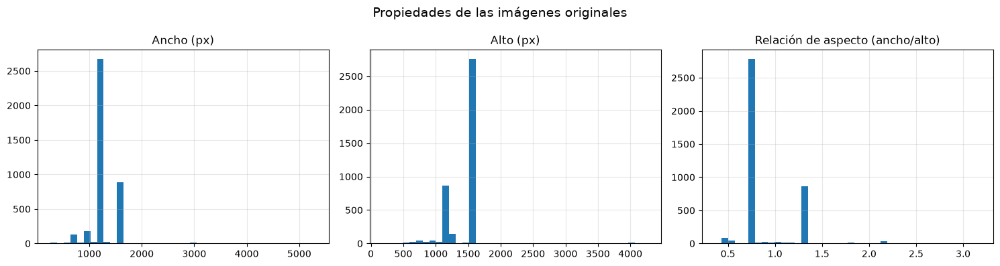

In [8]:
df_ok["aspecto"] = df_ok["ancho"] / df_ok["alto"]

print(df_ok[["ancho", "alto", "aspecto", "tam_kb"]].describe().round(2).to_string())
print("\nCanales :", dict(Counter(df_ok["canales"])))
print("Modos   :", dict(Counter(df_ok["modo"])))
print("Formatos:", dict(Counter(df_ok["formato"])))
print("\nImágenes con el lado menor < 128 px:", int((df_ok[["ancho", "alto"]].min(axis=1) < 128).sum()))
print("Imágenes con el lado menor < 224 px:", int((df_ok[["ancho", "alto"]].min(axis=1) < 224).sum()))

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for e, col, tit in zip(ejes, ["ancho", "alto", "aspecto"],
                       ["Ancho (px)", "Alto (px)", "Relación de aspecto (ancho/alto)"]):
    e.hist(df_ok[col], bins=40)
    e.set_title(tit)
    e.grid(alpha=0.3)
plt.suptitle("Propiedades de las imágenes originales", fontsize=14)
plt.tight_layout()
plt.show()

## 3.5 Imágenes duplicadas

Si una misma foto está en train y en test, el modelo la memoriza y la accuracy sale inflada. Por eso se detectan los duplicados **antes** de dividir los datos. Se usan dos huellas:

- **Hash exacto (MD5):** mismos bytes, misma huella.
- **Hash aproximado:** detecta copias casi idénticas (reescaladas, recomprimidas). Puede dar falsos positivos con fotos distintas pero muy parecidas, por eso se **revisan algunos grupos a simple vista**.

Se eliminan (1) las imágenes cuya huella aparece con **etiquetas distintas** (contradictorias) y (2) las copias repetidas, conservando una sola. `CLAVE_DUP` elige qué huella se usa para eliminar: si la revisión visual muestra que el hash aproximado agrupa fotos que **no** son copias, se cambia a `"h_ex"`. El resultado es `df_limpio`, el conjunto que se usará desde la Fase 4. No se detectan fotos distintas del mismo plato.

In [10]:
def cargar(ruta, lado=256):
    """Abre una imagen para mostrarla (corrige la rotación guardada en los metadatos)."""
    with Image.open(ruta) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im.thumbnail((lado, lado))
        return im.copy()

CLAVE_DUP = "h_ap"        # "h_ap" = copias casi idénticas | "h_ex" = solo copias exactas

print("Imágenes con hash exacto repetido    :", int(df_ok.duplicated("h_ex", keep=False).sum()))
print("Imágenes con hash aproximado repetido:", int(df_ok.duplicated("h_ap", keep=False).sum()))

n_cl = df_ok.groupby(CLAVE_DUP)["clase"].nunique()
contradictorias = n_cl[n_cl > 1].index
print(f"Huellas con etiquetas contradictorias ({CLAVE_DUP}):", len(contradictorias))

# Revisión visual de algunos grupos de duplicados
grupos = [g for _, g in df_ok[df_ok.duplicated(CLAVE_DUP, keep=False)].groupby(CLAVE_DUP)][:4]
if grupos:
    fig, ejes = plt.subplots(len(grupos), 3, figsize=(10, 3.2 * len(grupos)), squeeze=False)
    for e in ejes.ravel():
        e.axis("off")
    for i, g in enumerate(grupos):
        for j, (_, fila) in enumerate(g.head(3).iterrows()):
            ejes[i, j].imshow(cargar(fila["ruta"]))
            ejes[i, j].set_title(fila["clase"], fontsize=9)
    plt.suptitle("Grupos de duplicados detectados (cada fila es un grupo)", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron duplicados.")

# Limpieza: quitar contradictorias y quedarse con una sola copia
sin_contra = df_ok[~df_ok[CLAVE_DUP].isin(contradictorias)]
df_limpio = sin_contra.drop_duplicates(CLAVE_DUP, keep="first").reset_index(drop=True)
print("\nImágenes originales :", len(df_total))
print("Imágenes limpias    :", len(df_limpio), "| eliminadas:", len(df_total) - len(df_limpio))

comp = pd.DataFrame({
    "original": df_total["clase"].value_counts().reindex(CLASES),
    "limpias": df_limpio["clase"].value_counts().reindex(CLASES),
})
comp["eliminadas"] = comp["original"] - comp["limpias"]
if (comp["eliminadas"] > 0).any():
    print("\nClases afectadas:")
    print(comp[comp["eliminadas"] > 0].to_string())

Imágenes con hash exacto repetido    : 0
Imágenes con hash aproximado repetido: 0
Huellas con etiquetas contradictorias (h_ap): 0
No se encontraron duplicados.

Imágenes originales : 4000
Imágenes limpias    : 4000 | eliminadas: 0


## 3.6 Ruido visual: brillo, contraste y nitidez

Fotos muy oscuras, muy claras o desenfocadas pueden confundir al modelo. Se grafican las distribuciones de las tres medidas calculadas en 3.2 y se muestran los casos extremos (las más oscuras, las más brillantes y las más desenfocadas). La nitidez se grafica en escala logarítmica porque sus valores son muy asimétricos.

Esta sección ayuda a decidir si conviene aplicar *data augmentation* de brillo y contraste en la Fase 4.

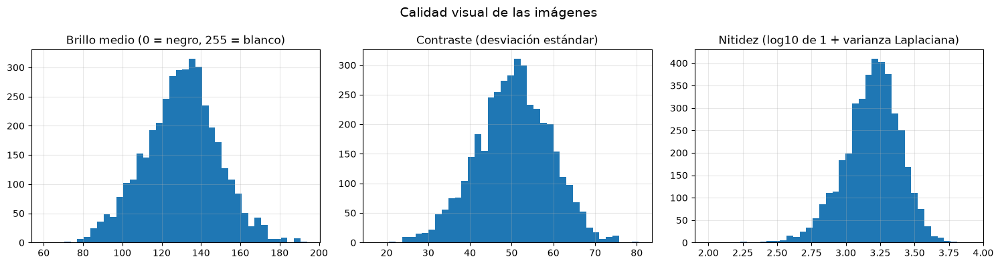

        brillo  contraste  nitidez
count  4000.00    4000.00  4000.00
mean    129.99      50.45  1717.53
std      18.56       8.84   772.72
min      60.37      17.46    97.76
25%     117.98      44.87  1180.67
50%     130.66      50.64  1603.99
75%     141.91      56.55  2121.77
max     193.99      80.47  8055.51


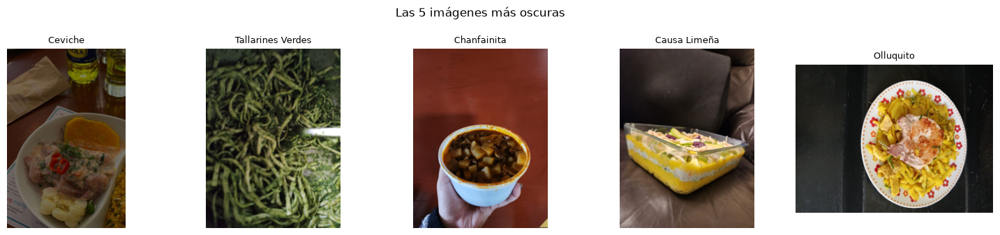

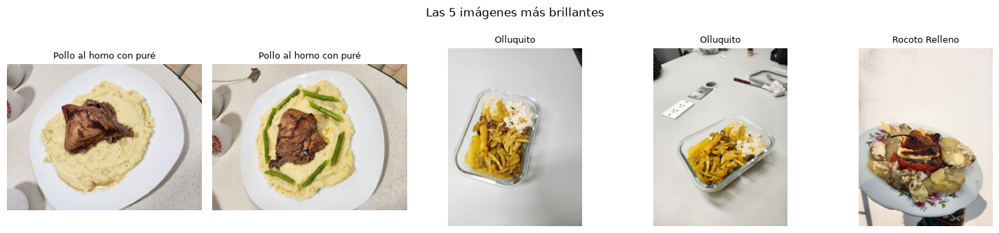

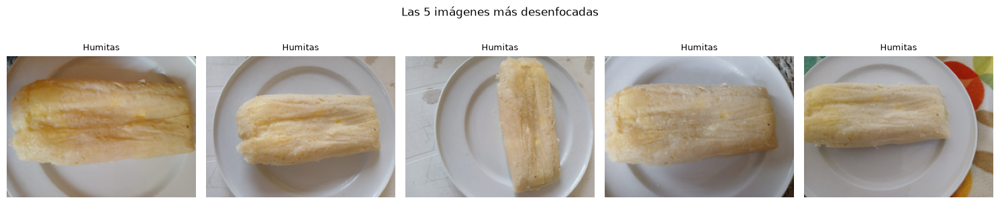

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(df_limpio["brillo"], bins=40)
ejes[0].set_title("Brillo medio (0 = negro, 255 = blanco)")
ejes[1].hist(df_limpio["contraste"], bins=40)
ejes[1].set_title("Contraste (desviación estándar)")
ejes[2].hist(np.log10(1 + df_limpio["nitidez"]), bins=40)
ejes[2].set_title("Nitidez (log10 de 1 + varianza Laplaciana)")
for e in ejes:
    e.grid(alpha=0.3)
plt.suptitle("Calidad visual de las imágenes", fontsize=14)
plt.tight_layout()
plt.show()

print(df_limpio[["brillo", "contraste", "nitidez"]].describe().round(2).to_string())

def mostrar(df, titulo, n=5):
    fig, ejes = plt.subplots(1, n, figsize=(3 * n, 3.4))
    for e, (_, f) in zip(ejes, df.head(n).iterrows()):
        e.imshow(cargar(f["ruta"]))
        e.set_title(f["clase"], fontsize=9)
        e.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

mostrar(df_limpio.nsmallest(5, "brillo"), "Las 5 imágenes más oscuras")
mostrar(df_limpio.nlargest(5, "brillo"), "Las 5 imágenes más brillantes")
mostrar(df_limpio.nsmallest(5, "nitidez"), "Las 5 imágenes más desenfocadas")

## 3.7 Grilla de ejemplos: una imagen por plato

`plt.subplots` crea una cuadrícula con una celda por clase. De cada plato se elige una imagen al azar (reproducible con `SEED`) y se muestra con `imshow`, con el nombre de la clase como título. Sirve para revisar visualmente que las imágenes sean fotos reales y correspondan a su clase, y para anticipar qué platos se parecen entre sí.

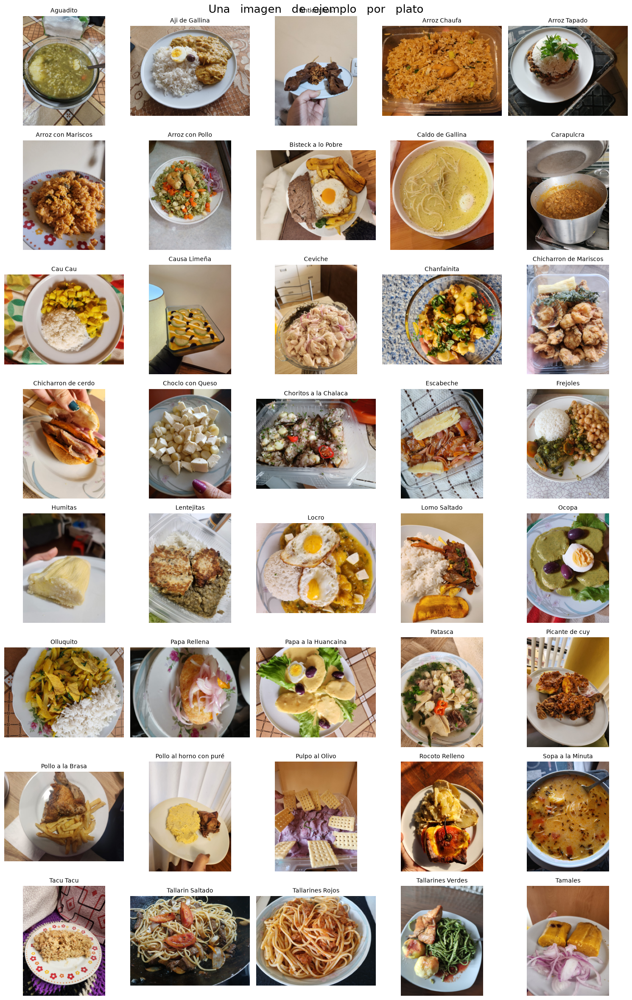

In [12]:
rng = np.random.default_rng(SEED)
columnas = 5
filas = -(-len(CLASES) // columnas)       # división hacia arriba

fig, ejes = plt.subplots(filas, columnas, figsize=(15, 3 * filas))
for e in ejes.ravel():
    e.axis("off")

for i, nombre in enumerate(CLASES):
    sub = df_limpio[df_limpio["clase"] == nombre]
    fila = sub.iloc[rng.integers(len(sub))]
    ejes.ravel()[i].imshow(cargar(fila["ruta"]))
    ejes.ravel()[i].set_title(nombre, fontsize=10)

plt.suptitle("Una   imagen   de  ejemplo   por   plato", fontsize=19)
plt.tight_layout()
plt.show()

## 3.8 Variabilidad dentro de una clase

Una sola imagen por plato no muestra cuánto varía un mismo plato entre fotos (ángulo, iluminación, presentación, fondo). Se muestran 10 imágenes de una misma clase (`CLASE_DEMO`, que se puede cambiar por cualquier otro plato). Mientras mayor sea esa variabilidad y menor la cantidad de imágenes por clase, más difícil será aprender el patrón, y más útil será el *data augmentation*.

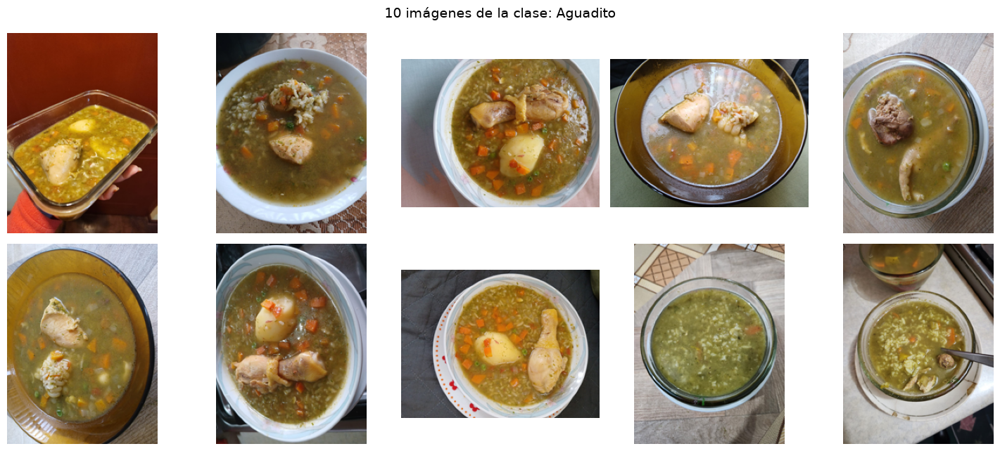

In [13]:
CLASE_DEMO = CLASES[0]        # cambiar por otro plato para explorar

sub = df_limpio[df_limpio["clase"] == CLASE_DEMO].sample(10, random_state=SEED)
fig, ejes = plt.subplots(2, 5, figsize=(15, 6.5))
for e, (_, f) in zip(ejes.ravel(), sub.iterrows()):
    e.imshow(cargar(f["ruta"]))
    e.axis("off")
plt.suptitle(f"10 imágenes de la clase: {CLASE_DEMO}", fontsize=14)
plt.tight_layout()
plt.show()

# Fase 3a: Preprocesamiento

El preprocesamiento convierte las fotos originales en tensores listos para la red. Se hace en este orden, que importa:

1. **Cargar y redimensionar** todas las imágenes a un tamaño fijo.
2. **Dividir** en entrenamiento, validación y prueba (antes de cualquier aumento).
3. **Normalizar** los píxeles al rango [0, 1].
4. **Data augmentation**, solo sobre el entrenamiento.

> **Regla de oro:** nunca se aplica *data augmentation* a los conjuntos de validación o prueba; deben medir el rendimiento sobre imágenes reales, sin alterar.

## 3.9 Parámetros de preprocesamiento

| Parámetro | Valor | Justificación |
|---|---|---|
| `IMG_SIZE` | 224 | Según el EDA, solo 4 de las 4,000 imágenes tienen el lado menor por debajo de 224 px, así que casi ninguna se amplía. Es el tamaño que usa la guía del curso. |
| `AJUSTE` | `"estirar"` | Las fotos tienen aspecto variable (mediana 0.75). Se redimensionan directamente a un cuadrado, sin perder contenido; la deformación se aplica igual a todas las imágenes, incluidas las de producción. La alternativa `"recortar"` toma el centro de la foto. |
| `TEST_SIZE` | 0.15 | 15% para prueba (15 imágenes por plato). |
| `VAL_SIZE` | 0.15 | 15% para validación (15 imágenes por plato); el 70% restante queda para entrenamiento. |

In [14]:
from sklearn.model_selection import train_test_split
from keras import layers

IMG_SIZE = 224
AJUSTE = "estirar"        # "estirar" = redimensiona a cuadrado | "recortar" = recorte central
TEST_SIZE = 0.15
VAL_SIZE = 0.15

N_CLASES = len(CLASES)
FORMA_ENTRADA = (IMG_SIZE, IMG_SIZE, 3)
print("Entrada:", FORMA_ENTRADA, "| Clases:", N_CLASES, "| Ajuste:", AJUSTE)

Entrada: (224, 224, 3) | Clases: 40 | Ajuste: estirar


## 3.10 Cargar y redimensionar las imágenes

La función `preparar_imagen` abre cada foto, **corrige la rotación guardada en los metadatos** (`exif_transpose`, para que las fotos tomadas con el celular no queden giradas), la convierte a RGB y la redimensiona a `IMG_SIZE × IMG_SIZE`. El resultado es un arreglo de NumPy de enteros de 8 bits (`uint8`, valores de 0 a 255). `Image.draft` acelera la lectura de JPEG decodificándolos ya a menor tamaño.

Esta misma función se **reutilizará en el despliegue** (Fase 12), para que el servicio prepare las fotos exactamente igual que en el entrenamiento. El resultado se guarda en disco con `np.save` (caché): la primera vez tarda un poco y las siguientes, segundos.

In [15]:
CACHE_X = PROYECTO / "data" / "processed" / f"cache_perufoodnet_{IMG_SIZE}px_{AJUSTE}.npy"

def preparar_imagen(ruta):
    """Abre, corrige la rotación, convierte a RGB y redimensiona a IMG_SIZE x IMG_SIZE."""
    with Image.open(ruta) as im:
        im.draft("RGB", (IMG_SIZE * 2, IMG_SIZE * 2))
        im = ImageOps.exif_transpose(im).convert("RGB")
        if AJUSTE == "recortar":
            im = ImageOps.fit(im, (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        else:
            im = im.resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        return np.asarray(im, dtype=np.uint8)

if CACHE_X.exists():
    X_all = np.load(CACHE_X)
    print("Cargado desde caché")
else:
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=8) as ex:
        X_all = np.stack(list(tqdm(ex.map(preparar_imagen, df_limpio["ruta"]),
                                   total=len(df_limpio), desc="Cargando")))
    np.save(CACHE_X, X_all)
    print(f"Cargadas y guardadas en caché en {time.time() - t0:.0f} s")

assert len(X_all) == len(df_limpio), "La caché no coincide con df_limpio: borra el archivo cache_perufoodnet_*"
y_all = df_limpio["clase"].map(clase_a_id).to_numpy(dtype="int64")
print("X_all:", X_all.shape, X_all.dtype, f"| {X_all.nbytes / 1e6:.0f} MB")

Cargado desde caché
X_all: (4000, 224, 224, 3) uint8 | 602 MB


## 3.11 División estratificada: entrenamiento, validación y prueba

Se dividen los datos en tres conjuntos con `train_test_split(..., stratify=y)`, que conserva la misma proporción de cada plato en todos los conjuntos:

- **Entrenamiento (70%):** con él la red ajusta sus pesos.
- **Validación (15%):** se usa durante el entrenamiento para vigilar el sobreajuste y elegir la mejor época. No ajusta pesos.
- **Prueba (15%):** se reserva hasta la evaluación final (Fase 6). No se toca antes.

La división se hace **antes** de aplicar el *data augmentation*, y en dos pasos: primero se separa la prueba y luego la validación del resto (por eso `VAL_SIZE` se reescala dividiendo entre `1 - TEST_SIZE`). Se guardan también las tablas con la ruta y la clase de cada conjunto, que servirán en el análisis de errores. Como se eliminaron los duplicados en el EDA, ninguna imagen debe estar en dos conjuntos a la vez, y se comprueba comparando sus huellas.

In [16]:
idx = np.arange(len(X_all))
idx_trval, idx_test = train_test_split(
    idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED
)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=y_all[idx_trval], random_state=SEED
)

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]

df_train = df_limpio.iloc[idx_train].reset_index(drop=True)
df_val = df_limpio.iloc[idx_val].reset_index(drop=True)
df_test = df_limpio.iloc[idx_test].reset_index(drop=True)
del X_all

# Comprobaciones: sin solapamiento entre conjuntos y proporciones por clase
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) \
    and not (set(idx_val) & set(idx_test))
fuga = len(set(df_train["h_ap"]) & set(df_test["h_ap"])) + len(set(df_val["h_ap"]) & set(df_test["h_ap"]))
print("Imágenes de test con copia en train o validación:", fuga)

for nombre, y in [("Train", y_train), ("Validación", y_val), ("Test", y_test)]:
    c = np.bincount(y, minlength=N_CLASES)
    print(f"{nombre:<11}: {len(y)} imágenes | por clase: mín {c.min()}, máx {c.max()}")

Imágenes de test con copia en train o validación: 0
Train      : 2800 imágenes | por clase: mín 70, máx 70
Validación : 600 imágenes | por clase: mín 15, máx 15
Test       : 600 imágenes | por clase: mín 15, máx 15


## 3.12 Normalización de los píxeles a [0, 1]

Los píxeles son enteros de 0 a 255. Se convierten a decimales (`float32`) y se dividen entre 255 para llevarlos al rango **[0, 1]**: la red entrena de forma más estable con valores pequeños. La misma operación se aplica a los tres conjuntos. Las imágenes ya tienen la forma `(N, alto, ancho, 3)` que espera una CNN, así que no hace falta cambiar su forma; se comprueba con `assert`.

In [17]:
print("Antes   :", X_train.dtype, "| mín:", X_train.min(), "| máx:", X_train.max())

X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Después :", X_train.dtype, "| mín:", X_train.min(), "| máx:", X_train.max())
assert X_train.ndim == 4 and X_train.shape[1:] == FORMA_ENTRADA
print("Forma por imagen:", X_train.shape[1:])

Antes   : uint8 | mín: 0 | máx: 255
Después : float32 | mín: 0.0 | máx: 1.0
Forma por imagen: (224, 224, 3)


## 3.13 Data augmentation (solo entrenamiento)

Con apenas 70 imágenes de entrenamiento por plato, la red tiende a memorizarlas. El *data augmentation* genera en cada época variaciones aleatorias de cada foto, de modo que la red nunca ve exactamente la misma imagen. El criterio de la guía es el **principio rectificador**: toda transformación debe producir una imagen que podría existir en el mundo real.

| Técnica | ¿Se aplica? | Justificación para fotos de comida |
|---|---|---|
| Giro horizontal | Sí | Un plato no tiene orientación izquierda/derecha "correcta"; no hay texto que se invierta. |
| Giro vertical | **No** | Una foto de comida de lado, puesta al revés, no es realista (gravedad fija). |
| Rotación (±36°, `0.1`) | Sí | Las fotos se toman con distintas inclinaciones del celular. |
| Zoom (15%) | Sí | Hay fotos tomadas a distintas distancias. |
| Brillo y contraste (suaves) | Sí | El EDA mostró variación de iluminación (brillo medio de 60 a 194). |
| Cambios de color (matiz) | **No** | El color es una pista clave para distinguir platos. |

Las capas de augmentation de Keras se incluyen **dentro del modelo** (Fase 4): solo actúan cuando `training=True` y se desactivan solas al validar, evaluar o predecir. `value_range=(0, 1)` indica a las capas de brillo y contraste que los píxeles ya están normalizados. Para visualizar, se pasa una misma imagen varias veces por el bloque con `training=True`; cada pasada da una variación distinta.

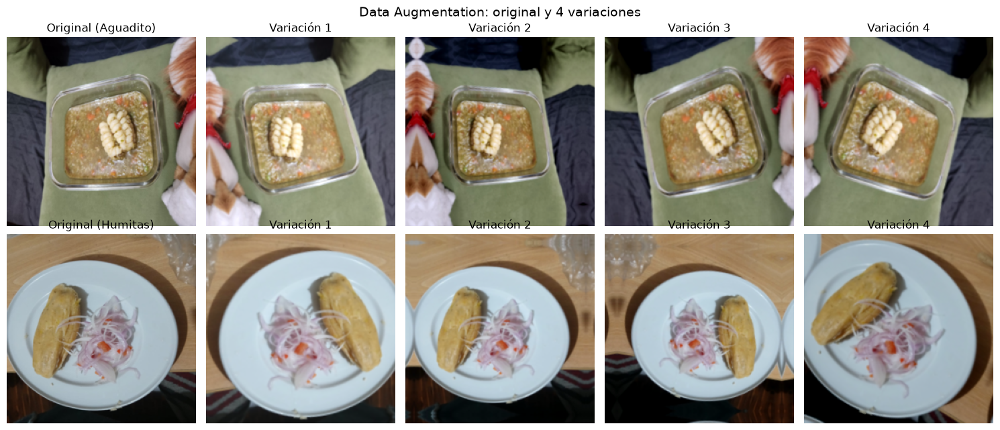

In [18]:
def crear_aumento():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),                             # hasta ±36°
        layers.RandomZoom(0.15),
        layers.RandomBrightness(0.1, value_range=(0, 1)),
        layers.RandomContrast(0.15, value_range=(0, 1)),
    ], name="aumento")

aug_demo = crear_aumento()
rng = np.random.default_rng(SEED)
ejemplos = [rng.choice(np.where(y_train == c)[0]) for c in (0, N_CLASES // 2)]   # dos platos distintos

fig, ejes = plt.subplots(2, 5, figsize=(15, 6.5))
for fila, j in enumerate(ejemplos):
    ejes[fila, 0].imshow(X_train[j])
    ejes[fila, 0].set_title(f"Original ({CLASES[y_train[j]]})")
    for k in range(1, 5):
        v = aug_demo(X_train[j][None], training=True)
        v = keras.ops.convert_to_numpy(v)[0]
        ejes[fila, k].imshow(np.clip(v, 0, 1))
        ejes[fila, k].set_title(f"Variación {k}")
for e in ejes.ravel():
    e.axis("off")
plt.suptitle("Data Augmentation: original y 4 variaciones", fontsize=14)
plt.tight_layout()
plt.show()

## 3.13.1 Verificación de la regla de oro

Se comprueba que las capas de augmentation **solo modifican las imágenes en entrenamiento** (`training=True`) y que dejan intactas las de validación y prueba (`training=False`). Así se garantiza que la validación y la prueba se evalúan sobre imágenes reales, sin alterar.

In [19]:
x = X_val[:8]
sin_aug = keras.ops.convert_to_numpy(aug_demo(x, training=False))
con_aug = keras.ops.convert_to_numpy(aug_demo(x, training=True))

print("Con training=False (val/test), la imagen queda idéntica:", np.allclose(sin_aug, x))
print("Con training=True (train), la imagen se modifica      :", not np.allclose(con_aug, x))

Con training=False (val/test), la imagen queda idéntica: True
Con training=True (train), la imagen se modifica      : True


## 3.14 Resumen del preprocesamiento

Tabla con el número de imágenes y la forma final de cada conjunto. `X` contiene las imágenes y `y` las etiquetas enteras (0 a 39).

In [20]:
resumen = pd.DataFrame({
    "Conjunto": ["Train", "Validación", "Test"],
    "Imágenes": [len(X_train), len(X_val), len(X_test)],
    "Shape X": [X_train.shape, X_val.shape, X_test.shape],
    "Shape y": [y_train.shape, y_val.shape, y_test.shape],
    "Augmentation": ["Sí (dentro del modelo)", "No", "No"],
})
print(resumen.to_string(index=False))
print("\nTotal de imágenes usadas:", len(X_train) + len(X_val) + len(X_test))
print("Clases:", N_CLASES, "| Rango de píxeles: [", X_train.min(), ",", X_train.max(), "]")

  Conjunto  Imágenes             Shape X Shape y           Augmentation
     Train      2800 (2800, 224, 224, 3) (2800,) Sí (dentro del modelo)
Validación       600  (600, 224, 224, 3)  (600,)                     No
      Test       600  (600, 224, 224, 3)  (600,)                     No

Total de imágenes usadas: 4000
Clases: 40 | Rango de píxeles: [ 0.0 , 1.0 ]


## 3.15 Conclusiones del EDA

- **Distribución de clases:** las 40 clases tienen exactamente 100 imágenes, con un ratio de desbalance de 1.0:1. El dataset está perfectamente balanceado, por lo que no hace falta submuestrear ni ponderar clases, y la accuracy global será una medida interpretable (el azar da 1/40 = 2.5%). El mínimo y el máximo coinciden, por eso la salida muestra el mismo plato en ambos.

- **Calidad de los archivos:** las 4,000 imágenes se abrieron y leyeron completas; no hay archivos corruptos ni truncados. Todas son JPEG en modo RGB de 3 canales, por lo que no se requiere ninguna conversión de formato ni de canales.

- **Dimensiones:** las imágenes originales son grandes y heterogéneas. La mediana es de 1200 × 1600 px (ancho × alto), pero van desde 265 × 185 hasta 5312 × 4270 px, y su peso va de 12 KB a unos 16 MB (mediana de 168 KB). Ninguna tiene el lado menor por debajo de 128 px y solo 4 lo tienen por debajo de 224 px, de modo que reducirlas a 128 × 128 o a 224 × 224 no obliga a ampliar casi ninguna imagen.

- **Relación de aspecto:** el valor más frecuente es 0.75 (fotos verticales de 3:4), pero el rango llega de 0.36 a 3.18, con una media de 0.90. Hay una mezcla de fotos verticales, cuadradas y horizontales, así que redimensionar todas a un cuadrado las deformará en distinta medida. Esto se tendrá en cuenta en el preprocesamiento.

- **Duplicados:** no se encontraron duplicados exactos ni aproximados, ni imágenes con etiquetas contradictorias. No hubo que eliminar ninguna imagen, por lo que `df_limpio` conserva las 4,000. Esta comprobación no detecta fotos distintas de un mismo plato.

- **Ruido visual:** el brillo medio es de 130 sobre 255 (rango de 60 a 194), el contraste medio es de 50 y la nitidez es muy variable (de 98 a 8,056 en la medida usada, con mediana de 1,604). No hay imágenes extremadamente oscuras ni quemadas, pero sí variación de iluminación y de enfoque entre fotos, coherente con el hecho de que se tomaron en distintos entornos, con distinta iluminación y con distintos dispositivos.

- **Variabilidad visual:** la revisión de las grillas muestra fotos reales de platos, con distintos ángulos, fondos y presentaciones dentro de una misma clase.

# Fase 4: Modelos (Baseline, CNN Mejorada y CNN Optimizada)

Se diseñan **tres arquitecturas de complejidad creciente** primero se confirma que el pipeline funciona de principio a fin con un modelo simple, y luego invertir en arquitecturas más complejas solo si aportan una mejora real.

| Modelo | Idea principal | Qué agrega respecto al anterior |
|---|---|---|
| **1. CNN Baseline** | 3 bloques `Conv + BatchNorm + ReLU + MaxPool` (32, 64, 128 filtros), `GlobalAveragePooling`, `Dense(256)` + `Dropout(0.5)` | Es la línea base de modelo: confirma que el pipeline funciona. |
| **2. CNN Mejorada (estilo ResNet)** | Bloques residuales con *skip connection* | Combate el desvanecimiento del gradiente y permite redes más profundas. |
| **3. CNN Optimizada Final** | Bloques residuales más profundos, con *stem* de *stride* agresivo, *data augmentation* dentro del modelo, L2 y Dropout escalonado | Reduce el sobreajuste y la memoria usada, con las optimizaciones de la sesión 06. |

**Decisiones comunes a los tres modelos:**
- **Entrada:** `(224, 224, 3)`; **salida:** `Dense(40, activation="softmax")`, una neurona por plato (Fase 1).
- **Batch Normalization antes de la activación:** normaliza la salida lineal de la convolución y `ReLU` recibe valores centrados. Como `BatchNormalization` ya incluye su propio desplazamiento (`beta`), las convoluciones usan `use_bias=False`.
- **`GlobalAveragePooling2D` (GAP)** en lugar de `Flatten`: promedia cada mapa de rasgos en un solo número, lo que reduce mucho los parámetros del clasificador. En la Actividad 2, `Flatten + Dense(128)` concentraba el 97.8% de los parámetros y causó un sobreajuste severo.
- Los modelos **solo se construyen aquí**; se compilan y se entrenan en la Fase 5.

## 4.1 Modelo 1: CNN Baseline

Tres bloques convolucionales que duplican los filtros (32, 64, 128): las primeras capas detectan rasgos simples (bordes, colores) y las siguientes, combinaciones más complejas (texturas, formas del plato). Después, `GlobalAveragePooling2D`, una capa `Dense(256)` con `Dropout(0.5)` y la capa de salida con `softmax`.

- `Conv2D(filtros, 3, padding="same")`: ventanas de 3×3 que recorren la imagen; `padding="same"` conserva el alto y ancho.
- `BatchNormalization()`: normaliza la salida de la capa por lote (media 0, desviación 1) y estabiliza el entrenamiento.
- `MaxPooling2D(2)`: reduce a la mitad el alto y ancho, quedándose con el máximo de cada ventana de 2×2.
- `Dropout(0.5)`: apaga al azar el 50% de las neuronas en cada paso de entrenamiento, para que no memoricen.

Siguiendo las diapositivas, este modelo **no** incluye *data augmentation*; se usa solo para confirmar que el pipeline funciona.

In [21]:
from keras import regularizers

def crear_cnn_baseline(forma=FORMA_ENTRADA, n_clases=N_CLASES):
    capas = [keras.Input(shape=forma)]
    for filtros in (32, 64, 128):
        capas += [
            layers.Conv2D(filtros, 3, padding="same", use_bias=False),
            layers.BatchNormalization(),
            layers.Activation("relu"),
            layers.MaxPooling2D(2),
        ]
    capas += [
        layers.GlobalAveragePooling2D(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(n_clases, activation="softmax"),
    ]
    return keras.Sequential(capas, name="cnn_baseline")

modelo_1 = crear_cnn_baseline()
modelo_1.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │        10,280 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137,224 (536.03 KB)

 Trainable params: 136,776 (534.28 KB)

 Non-trainable params: 448 (1.75 KB)

## 4.2 Bloque residual (*skip connection*)

En una red muy profunda, el gradiente (la señal que indica cómo corregir los pesos) se debilita al atravesar muchas capas y las primeras casi no aprenden: es el **desvanecimiento del gradiente**. Un **bloque residual** lo combate sumando a la salida de dos convoluciones la entrada original (el *atajo* o *shortcut*), de modo que el gradiente tiene un camino directo hacia atrás:

```
x ─→ Conv → BN → ReLU → Conv → BN ─→ (+) → ReLU
 └────────────── atajo ───────────────┘
```

- `layers.Add()` suma la ruta principal y el atajo; ambos deben tener la misma forma.
- **Atajo con proyección:** cuando el bloque cambia el número de filtros o reduce el tamaño (`stride=2`), la entrada ya no tiene la misma forma que la salida. En ese caso el atajo pasa por una convolución de 1×1 (con su `BatchNormalization`) que la ajusta. La diapositiva muestra el caso más simple, con `shortcut = x`, y esta variante lo extiende para que el bloque funcione con cualquier cambio de filtros.
- `stride=2` reduce a la mitad el alto y ancho, y reemplaza al `MaxPooling` dentro de las etapas.
- `l2` aplica regularización L2 a los pesos de las convoluciones (se usa en el Modelo 3).

In [24]:
def bloque_residual(x, filtros, stride=1, l2=0.0):
    reg = regularizers.l2(l2) if l2 else None
    atajo = x

    # Ruta principal
    x = layers.Conv2D(filtros, 3, strides=stride, padding="same",
                      use_bias=False, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filtros, 3, padding="same",
                      use_bias=False, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)

    # Atajo: si cambia la forma, se proyecta con una convolución 1x1
    if stride != 1 or atajo.shape[-1] != filtros:
        atajo = layers.Conv2D(filtros, 1, strides=stride, padding="same",
                              use_bias=False, kernel_regularizer=reg)(atajo)
        atajo = layers.BatchNormalization()(atajo)

    # SUMA (skip connection)
    x = layers.Add()([x, atajo])
    return layers.Activation("relu")(x)

## 4.3 Modelo 2: CNN Mejorada (estilo ResNet)

Un *stem* inicial (`Conv 3×3` + BN + ReLU + `MaxPool`) seguido de **cuatro etapas de un bloque residual** (32, 64, 128 y 256 filtros), donde las etapas 2 a 4 reducen el tamaño con `stride=2`. Cierra con `GlobalAveragePooling2D`, `Dense(256)`, `Dropout(0.5)` y la capa `softmax`. Se construye con la **API funcional** de Keras (`keras.Model(entradas, salidas)`), porque la suma del atajo no puede expresarse con `Sequential`.

Igual que el Modelo 1, no incluye *data augmentation*: así, la diferencia entre ambos mide el efecto de los bloques residuales y la mayor profundidad.

In [25]:
ETAPAS_MEJORADA = [(32, 1), (64, 2), (128, 2), (256, 2)]      # (filtros, stride)

def crear_cnn_mejorada(forma=FORMA_ENTRADA, n_clases=N_CLASES):
    entradas = keras.Input(shape=forma)

    # Stem
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(entradas)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(2)(x)

    # Etapas residuales
    for filtros, stride in ETAPAS_MEJORADA:
        x = bloque_residual(x, filtros, stride)

    # Clasificador
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    salidas = layers.Dense(n_clases, activation="softmax")(x)
    return keras.Model(entradas, salidas, name="cnn_mejorada_resnet")

modelo_2 = crear_cnn_mejorada()
modelo_2.summary()

Model: "cnn_mejorada_resnet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 224, 224,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 224, 224,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 224, 224,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 112, 112,  │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 112, 112,  │      9,216 │ max_pooling2d_3[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 112, 112,  │      9,216 │ activation_4[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_5        │ (None, 112, 112,  │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 56, 56,    │     18,432 │ activation_5[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_6        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 56, 56,    │     36,864 │ activation_6[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 56, 56,    │      2,048 │ activation_5[0][

 Total params: 1,305,352 (4.98 MB)

 Trainable params: 1,302,472 (4.97 MB)

 Non-trainable params: 2,880 (11.25 KB)

## 4.4 Modelo 3: CNN Optimizada Final

Es la arquitectura del Modelo 2, **más profunda** (dos bloques residuales por etapa) y con las optimizaciones de la sesión 06 aplicadas:

1. **Data augmentation incrustado en el grafo:** `crear_aumento()` (Fase 3) es la primera capa del modelo; solo actúa en entrenamiento y se desactiva sola al validar, evaluar o predecir. Por eso, al entrenar este modelo se le pasan las imágenes **sin** aumentar.
2. ***Stem* con *stride* agresivo:** una convolución de 7×7 con `stride=2` seguida de `MaxPooling(3, stride=2)` reduce la imagen de 224×224 a 56×56 de inmediato. Así, las etapas siguientes procesan mapas mucho más pequeños, con menos memoria y menos cómputo.
3. **Regularización L2 (1e-4)** en todas las capas convolucionales y densas.
4. **Dropout escalonado:** `SpatialDropout2D` (apaga mapas de rasgos completos, más adecuado para convoluciones) con tasas crecientes de 0.10, 0.15 y 0.20 en las etapas 2 a 4, y luego `Dropout(0.5)` antes de la salida. Obliga a la red a repartir la información en varias neuronas (redundancia).


In [26]:
L2 = 1e-4
ETAPAS_OPTIMIZADA = [(32, 1, 0.00), (64, 2, 0.10), (128, 2, 0.15), (256, 2, 0.20)]   # (filtros, stride, dropout)

def crear_cnn_optimizada(forma=FORMA_ENTRADA, n_clases=N_CLASES, l2=L2):
    reg = regularizers.l2(l2)
    entradas = keras.Input(shape=forma)
    x = crear_aumento()(entradas)                      # 1. Data augmentation incrustado

    # 2. Stem con stride agresivo: 224 -> 112 -> 56
    x = layers.Conv2D(32, 7, strides=2, padding="same", use_bias=False, kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    # Etapas residuales (dos bloques por etapa) con L2 y Dropout escalonado
    for filtros, stride, p in ETAPAS_OPTIMIZADA:
        x = bloque_residual(x, filtros, stride, l2)
        x = bloque_residual(x, filtros, 1, l2)
        if p:
            x = layers.SpatialDropout2D(p)(x)

    # Clasificador
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(0.5)(x)
    salidas = layers.Dense(n_clases, activation="softmax", kernel_regularizer=reg)(x)
    return keras.Model(entradas, salidas, name="cnn_optimizada")

modelo_3 = crear_cnn_optimizada()
modelo_3.summary()

Model: "cnn_optimizada"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ aumento             │ (None, 224, 224,  │          0 │ input_layer_3[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 112, 112,  │      4,704 │ aumento[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_15[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_12       │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 56, 56,    │          0 │ activation_12[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 56, 56,    │      9,216 │ max_pooling2d_4[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_16[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_13       │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 56, 56,    │      9,216 │ activation_13[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_17[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ max_pooling2d_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_14       │ (None, 56, 56,    │          0 │ add_4[0][0]       │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 56, 56,    │      9,216 │ activation_14[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_18[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_15       │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 56, 56,    │      9,216 │ activation_15[0]

 Total params: 2,879,752 (10.99 MB)

 Trainable params: 2,874,952 (10.97 MB)

 Non-trainable params: 4,800 (18.75 KB)

## 4.5 Comparación de las arquitecturas

Se reúnen en una tabla los **parámetros totales** (los números que la red ajusta al entrenar), los **entrenables** (los que realmente se actualizan; los restantes son las estadísticas de `BatchNormalization`) y el **peso aproximado** del modelo en MB, calculado como parámetros × 4 bytes (`float32`). El peso importa por la restricción de la Fase 1: el modelo debe pesar menos de 50 MB.

Además se hace una **prueba de humo**: se pasan 4 imágenes por cada modelo y se comprueba que la salida tiene la forma `(4, 40)` y que cada fila suma 1 (son probabilidades de `softmax`). Con eso se confirma que las tres arquitecturas están bien conectadas antes de entrenarlas.

In [40]:
modelos = [modelo_1, modelo_2, modelo_3]
filas = []
for m in modelos:
    total = m.count_params()
    entrenables = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
    filas.append({
        "Arquitectura": m.name,
        "Parámetros totales": total,
        "Parámetros entrenables": entrenables,
        "Peso aprox. (MB)": round(total * 4 / 1e6, 1),
        "Capas": len(m.layers),
        "Cumple < 50 MB": total * 4 / 1e6 < 50,
    })
tabla_modelos = pd.DataFrame(filas)
print(tabla_modelos.to_string(index=False))

# Prueba de humo: forma y suma de probabilidades
x_prueba = X_train[:4]
for m in modelos:
    p = keras.ops.convert_to_numpy(m(x_prueba, training=False))
    print(f"{m.name:<22} salida {p.shape} | suma por fila: {p.sum(axis=1).round(3)}")

       Arquitectura  Parámetros totales  Parámetros entrenables  Peso aprox. (MB)  Capas  Cumple < 50 MB
       cnn_baseline              137224                  136776               0.5     16            True
cnn_mejorada_resnet             1305352                 1302472               5.2     43            True
     cnn_optimizada             2879752                 2874952              11.5     75            True
cnn_baseline           salida (4, 40) | suma por fila: [1. 1. 1. 1.]
cnn_mejorada_resnet    salida (4, 40) | suma por fila: [1. 1. 1. 1.]
cnn_optimizada         salida (4, 40) | suma por fila: [1. 1. 1. 1.]


## 4.6 Conclusiones de la Fase 4

Los tres modelos se construyeron correctamente: aceptan imágenes de 224 × 224 × 3 y devuelven un vector de 40 probabilidades que suma 1 por imagen. Las arquitecturas aún no se han entrenado; sus resultados se compararán en las Fases 5 y 8.

| Arquitectura | Parámetros totales | Entrenables | Peso aprox. | Capas | Cumple < 50 MB |
|---|---|---|---|---|---|
| CNN Baseline | 137,224 | 136,776 | 0.5 MB | 16 | Sí |
| CNN Mejorada (ResNet) | 1,305,352 | 1,302,472 | 5.2 MB | 43 | Sí |
| CNN Optimizada | 2,879,752 | 2,874,952 | 11.5 MB | 75 | Sí |

- **Modelo 1 (Baseline):** es la arquitectura más pequeña, con 137,224 parámetros (0.5 MB). Tres bloques convolucionales (32, 64 y 128 filtros) reducen la imagen hasta mapas de 28 × 28 × 128, que `GlobalAveragePooling2D` resume en 128 valores. A diferencia de la CNN base de la Actividad 2, donde el clasificador denso concentraba el 97.8% de los parámetros, aquí el clasificador (`Dense(256)` y la salida) suma 43,304 parámetros, el 31.6% del total. Sirve como línea base de modelo para confirmar que el pipeline funciona.

- **Modelo 2 (Mejorada, estilo ResNet):** añade cuatro bloques residuales (32, 64, 128 y 256 filtros) y llega a 1,305,352 parámetros (5.2 MB), unas 9.5 veces el Baseline. Tres de los cuatro bloques cambian el número de filtros y reducen el tamaño, por lo que usan un atajo con proyección (convolución 1×1 de 2,048, 8,192 y 32,768 parámetros). El mapa final es de 14 × 14 × 256 y el clasificador pesa solo el 5.8% del total: casi todo el modelo es extractor de rasgos.

- **Modelo 3 (Optimizada):** duplica los bloques residuales (8 en total) y reúne las optimizaciones de la sesión 06: *data augmentation* como primera capa, *stem* de 7×7 con *stride* 2 y *max pooling* (224 → 56 de entrada a las etapas), L2 de 1e-4, `SpatialDropout2D` escalonado (0.10, 0.15 y 0.20) y `Dropout(0.5)` en el clasificador. Tiene 2,879,752 parámetros (11.5 MB), 2.2 veces el Modelo 2 y 21 veces el Baseline. Sus etapas trabajan con mapas de 56, 28, 14 y 7 píxeles de lado, frente a los 112, 56, 28 y 14 del Modelo 2, por lo que cada capa maneja cuatro veces menos activaciones en la entrada de las etapas, y el entrenamiento necesitará menos memoria de GPU que su tamaño sugiere.

- **Restricción de tamaño (< 50 MB):** los tres modelos la cumplen con margen. El más grande (Modelo 3, 11.5 MB) ocupa alrededor del 23% del límite, de modo que la restricción no limita la elección de la arquitectura. La conversión a TFLite o ONNX y la medición del tiempo de inferencia (< 1 s en CPU) se verifican en la Fase 12.

- **Limitación de la comparación:** el Modelo 3 cambia varias cosas a la vez respecto al Modelo 2 (profundidad, *stem*, augmentation, L2 y Dropout), por lo que una mejora no podrá atribuirse a una sola técnica. Si el tiempo lo permite, se puede entrenar una variante del Modelo 3 sin augmentation para aislar su efecto.

# Fase 5: Configuración del entrenamiento y callbacks

Esta fase define **cómo** aprenden los modelos (hiperparámetros, pérdida, métricas, callbacks) y entrena las tres arquitecturas de la Fase 4 con exactamente las mismas condiciones, para que la comparación sea justa. Solo se usan los conjuntos de entrenamiento y validación; el de prueba no se toca hasta la Fase 6.

## 5.1 Configuración centralizada (`CONFIG`)

Todos los hiperparámetros viven en **un solo diccionario**, que funciona como "panel de control": cambiar un valor aquí cambia el entrenamiento de los tres modelos, y el mismo diccionario se guarda junto a cada experimento para poder reproducirlo.

| Parámetro | Valor | Justificación |
|---|---|---|
| `learning_rate` | 1e-3 | Tamaño base del paso de Adam; es el valor estándar de la guía. |
| `epochs` | 50 | Es solo un **tope**: `EarlyStopping` detendrá el entrenamiento antes si deja de mejorar. |
| `batch_size` | 32 | Imágenes por lote (valor de la guía); con lotes más grandes se agotaría antes la memoria de la GPU. |
| `optimizer` | adam | Ajusta el paso de cada peso según el historial de sus gradientes. |
| `label_smoothing` | 0.1 | Suaviza las etiquetas (la clase correcta pasa de 1.0 a ≈ 0.9) para evitar que el modelo se vuelva demasiado confiado. |
| `weight_decay` | `None` | El Modelo 3 ya aplica L2 en sus capas; usar también *weight decay* aplicaría la regularización dos veces. |
| `early_stopping_patience` | 10 | Si `val_loss` no mejora en 10 épocas seguidas, se detiene y se restauran los mejores pesos. |
| `reduce_lr_patience` | 4 | Si `val_loss` no mejora en 4 épocas, se reduce el *learning rate*. |
| `reduce_lr_factor` / `min_lr` | 0.5 / 1e-6 | Se reduce a la mitad cada vez, sin bajar de 1e-6. |

`ReduceLROnPlateau` (paciencia 4) reacciona antes que `EarlyStopping` (paciencia 10): primero se prueba con pasos más pequeños y solo si tampoco mejora se corta el entrenamiento.

Los resultados se guardan en dos carpetas: `modelos/` (el mejor modelo de cada entrenamiento, en formato `.keras`) y `experimentos/` (el historial en CSV y JSON y los registros de cada corrida).

In [28]:
CONFIG = {
    "learning_rate": 1e-3,
    "epochs": 50,
    "batch_size": 32,
    "optimizer": "adam",
    "label_smoothing": 0.1,
    "weight_decay": None,            # el Modelo 3 ya tiene L2 en sus capas (no duplicar)
    "early_stopping_patience": 10,
    "reduce_lr_patience": 4,
    "reduce_lr_factor": 0.5,
    "min_lr": 1e-6,
    "seed": SEED,
    "img_size": IMG_SIZE,
    "n_clases": N_CLASES,
}

MODELOS_DIR = PROYECTO / "models"
EXP_DIR = PROYECTO / "experimentos"
MODELOS_DIR.mkdir(exist_ok=True)
EXP_DIR.mkdir(exist_ok=True)

pasos_por_epoca = -(-len(X_train) // CONFIG["batch_size"])
print("Imágenes de entrenamiento:", len(X_train), "| lotes por época:", pasos_por_epoca)
for k, v in CONFIG.items():
    print(f"  {k}: {v}")

Imágenes de entrenamiento: 2800 | lotes por época: 88
  learning_rate: 0.001
  epochs: 50
  batch_size: 32
  optimizer: adam
  label_smoothing: 0.1
  weight_decay: None
  early_stopping_patience: 10
  reduce_lr_patience: 4
  reduce_lr_factor: 0.5
  min_lr: 1e-06
  seed: 42
  img_size: 224
  n_clases: 40


## 5.2 Etiquetas en formato *one-hot*

Hasta ahora las etiquetas son números enteros (0 a 39). La pérdida con *label smoothing* y la métrica AUC necesitan que cada etiqueta sea un **vector *one-hot*** de 40 posiciones: un 1 en la posición de su clase y 0 en las demás (por ejemplo, la clase 2 es `[0, 0, 1, 0, ..., 0]`). `keras.utils.to_categorical` hace la conversión. Se conservan también las etiquetas enteras (`y_train`, `y_val`, `y_test`), porque las usarán las evaluaciones de las Fases 6 y 7.

In [29]:
y_train_oh = keras.utils.to_categorical(y_train, N_CLASES)
y_val_oh = keras.utils.to_categorical(y_val, N_CLASES)
y_test_oh = keras.utils.to_categorical(y_test, N_CLASES)

print("y_train:", y_train.shape, "->", y_train_oh.shape)
print("Ejemplo: clase", y_train[0], f"({CLASES[y_train[0]]}) ->", y_train_oh[0].astype(int))
assert (y_train_oh.argmax(axis=1) == y_train).all()

y_train: (2800,) -> (2800, 40)
Ejemplo: clase 18 (Escabeche) -> [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0]


## 5.3 Pérdida, optimizador y métricas

- **Optimizador `Adam`:** ajusta los pesos para reducir el error, adaptando el paso de cada peso según cómo han cambiado sus gradientes.
- **Pérdida `CategoricalCrossentropy(label_smoothing=0.1)`:** mide qué tan lejos están las probabilidades predichas de la clase correcta. Con *label smoothing*, el objetivo deja de ser 1.0 exacto y pasa a ≈ 0.9, repartiendo el resto entre las demás clases. No se usa `from_logits` porque la última capa ya aplica `softmax`.
- **Métricas:**
  - `accuracy`: porcentaje de imágenes bien clasificadas.
  - `top3`: porcentaje de imágenes cuyo plato correcto está entre las 3 predicciones más probables. Con 40 clases parecidas, indica si el modelo al menos "se acerca" cuando falla.
  - `auc`: área bajo la curva ROC (una curva por clase, `multi_label=True`), que mide qué tan bien se separa cada plato del resto.

> **Cómo leer la pérdida:** con *label smoothing* la pérdida **nunca llega a 0**, ni siquiera con un modelo perfecto, y la pérdida del Modelo 3 incluye además la penalización L2 de sus pesos. Por eso el `loss` **no sirve para comparar entre modelos**; para eso se usan `accuracy`, `top3`, `auc` y el F1 de las Fases 6 y 8. El `loss` solo se compara dentro de un mismo modelo, época tras época.

In [30]:
def crear_optimizador():
    return keras.optimizers.Adam(
        learning_rate=CONFIG["learning_rate"],
        weight_decay=CONFIG["weight_decay"],
    )

def crear_perdida():
    return keras.losses.CategoricalCrossentropy(label_smoothing=CONFIG["label_smoothing"])

def crear_metricas():
    return [
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.TopKCategoricalAccuracy(k=3, name="top3"),
        keras.metrics.AUC(name="auc", multi_label=True),
    ]

print("Optimizador:", crear_optimizador().__class__.__name__)
print("Pérdida    :", crear_perdida().__class__.__name__, "| label_smoothing =", CONFIG["label_smoothing"])
print("Métricas   :", [m.name for m in crear_metricas()])

Optimizador: Adam
Pérdida    : CategoricalCrossentropy | label_smoothing = 0.1
Métricas   : ['accuracy', 'top3', 'auc']


## 5.4 Callbacks de automatización

Un **callback** es un objeto que Keras ejecuta en momentos concretos del entrenamiento (al terminar un lote, una época, etc.). Permiten vigilar, ajustar y registrar el entrenamiento sin intervención humana:

| Callback | Qué hace |
|---|---|
| `ModelCheckpoint` | Guarda en disco **solo el mejor modelo** (menor `val_loss`), de modo que un fallo a mitad del entrenamiento no pierde el progreso. |
| `EarlyStopping` | Detiene el entrenamiento si `val_loss` no mejora y **restaura los pesos de la mejor época**, no los de la última. |
| `ReduceLROnPlateau` | Reduce el *learning rate* a la mitad cuando `val_loss` se estanca, para afinar el aprendizaje. |
| `TensorBoardTorch` (propio) | Telemetría interactiva en tiempo real. El callback `TensorBoard` de Keras depende de TensorFlow, que este proyecto no usa (el backend es PyTorch), por lo que se escribe un callback propio que registra las métricas de cada época con `torch.utils.tensorboard`. Requiere el paquete `tensorboard`; si no está instalado, se omite. |
| `CSVLogger` | Registro persistente en texto plano de cada época, para trazabilidad. |
| `BarraProgreso` (propio) | Barra de progreso con el tiempo restante y una línea de resumen por época, para ver en todo momento en qué época va el entrenamiento. |

En Windows, TensorBoard guarda sus eventos en una carpeta temporal única para evitar conflictos con archivos existentes y errores con rutas del proyecto que contienen caracteres no ASCII (como `í`). En PowerShell, `%TEMP%` no se expande como en CMD: copia y ejecuta el comando completo `tensorboard --logdir "..."` que imprime la celda de callbacks (incluye la ruta única). Abre `http://localhost:6006`. Los archivos CSV y JSON siguen en `experimentos/`.

Los callbacks se crean **de nuevo para cada entrenamiento** (`crear_callbacks`), porque guardan su propio estado y no deben compartirse entre modelos.

In [31]:
import importlib.util
import tempfile
from tqdm.auto import tqdm

TENSORBOARD_OK = importlib.util.find_spec("tensorboard") is not None
TENSORBOARD_DIR = Path(tempfile.mkdtemp(prefix="PeruFoodNet_TensorBoard_"))
print("TensorBoard disponible (paquete 'tensorboard' instalado):", TENSORBOARD_OK)
print("Directorio de eventos TensorBoard:", TENSORBOARD_DIR)
print(f'Para abrir TensorBoard: tensorboard --logdir "{TENSORBOARD_DIR}"')

class BarraProgreso(keras.callbacks.Callback):
    """Barra global (todos los lotes de todas las épocas) con tiempo restante
    y una línea de resumen al terminar cada época."""

    def on_train_begin(self, logs=None):
        self.epocas = self.params["epochs"]
        self.pasos = self.params["steps"]
        self.barra = tqdm(total=self.epocas * self.pasos, unit="lote",
                          desc="Entrenando", dynamic_ncols=True)
        self.epoca_actual = 0
        self.ultima_epoca = 0
        self.t_inicio = time.time()

    def on_epoch_begin(self, epoch, logs=None):
        self.epoca_actual = epoch + 1
        self.t_epoca = time.time()

    def on_train_batch_end(self, batch, logs=None):
        self.barra.set_postfix(
            época=f"{self.epoca_actual}/{self.epocas}",
            loss=f"{float(logs['loss']):.3f}",
            acc=f"{float(logs['accuracy']):.3f}",
        )
        self.barra.update(1)

    def on_test_begin(self, logs=None):
        if hasattr(self, "barra"):
            self.barra.set_postfix_str(f"época {self.epoca_actual}/{self.epocas} | validando...")

    def on_epoch_end(self, epoch, logs=None):
        self.ultima_epoca = epoch + 1
        lr = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))
        tqdm.write(
            f"Época {epoch + 1:>2}/{self.epocas} | {time.time() - self.t_epoca:>4.0f} s | lr {lr:.1e} | "
            f"loss {float(logs['loss']):.3f}  acc {float(logs['accuracy']):.3f} | "
            f"val_loss {float(logs['val_loss']):.3f}  val_acc {float(logs['val_accuracy']):.3f}  "
            f"val_top3 {float(logs.get('val_top3', float('nan'))):.3f}"
        )

    def on_train_end(self, logs=None):
        self.barra.close()
        total = time.time() - self.t_inicio
        print(f"Entrenamiento terminado: {self.ultima_epoca} épocas en {total / 60:.1f} min")

class TensorBoardTorch(keras.callbacks.Callback):
    """TensorBoard sin TensorFlow: registra las métricas de cada época
    con torch.utils.tensorboard."""

    def __init__(self, log_dir):
        super().__init__()
        from torch.utils.tensorboard import SummaryWriter
        self.escritor = SummaryWriter(log_dir=str(log_dir))

    def on_epoch_end(self, epoch, logs=None):
        for nombre, valor in (logs or {}).items():
            self.escritor.add_scalar(nombre, float(valor), epoch + 1)
        lr = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))
        self.escritor.add_scalar("learning_rate", lr, epoch + 1)
        self.escritor.flush()

    def on_train_end(self, logs=None):
        self.escritor.close()

def crear_callbacks(nombre):
    carpeta = EXP_DIR / nombre
    carpeta.mkdir(parents=True, exist_ok=True)
    cbs = [
        keras.callbacks.ModelCheckpoint(
            filepath=str(MODELOS_DIR / f"{nombre}.keras"),
            monitor="val_loss", save_best_only=True, verbose=0),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=CONFIG["early_stopping_patience"],
            restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=CONFIG["reduce_lr_factor"],
            patience=CONFIG["reduce_lr_patience"], min_lr=CONFIG["min_lr"], verbose=1),
        keras.callbacks.CSVLogger(str(carpeta / "entrenamiento.csv")),
    ]
    if TENSORBOARD_OK:
        try:
            cbs.append(TensorBoardTorch(TENSORBOARD_DIR / nombre))
        except Exception as e:                       # no detener el entrenamiento por esto
            print("TensorBoard omitido:", type(e).__name__, e)
    cbs.append(BarraProgreso())
    return cbs

TensorBoard disponible (paquete 'tensorboard' instalado): True
Directorio de eventos TensorBoard: C:\Users\USER\AppData\Local\Temp\PeruFoodNet_TensorBoard_prdtp2_e
Para abrir TensorBoard: tensorboard --logdir "C:\Users\USER\AppData\Local\Temp\PeruFoodNet_TensorBoard_prdtp2_e"


## 5.5 Función de entrenamiento reutilizable

La función `entrenar` hace, **siempre en el mismo orden y con el mismo `CONFIG`**, todo lo necesario para un modelo:

1. Fija la semilla (`set_random_seed`), de modo que los tres modelos parten de las mismas condiciones aleatorias.
2. Construye el modelo desde cero con su función `crear_...` (así `fit` no continúa desde pesos ya entrenados).
3. Lo compila con el optimizador, la pérdida y las métricas de 5.3.
4. Entrena con `fit`, usando validación y los callbacks de 5.4. `verbose=0` apaga la salida por defecto de Keras para no duplicar la de `BarraProgreso`.
5. Guarda un **resumen en JSON** (configuración, tiempo, mejor época, métricas e historial completo) en `experimentos/<nombre>/`, que servirá para la comparación (Fase 8), el versionado y el registro de experimentos.

Devuelve el modelo (con los pesos de la mejor época restaurados), el historial de Keras y el tiempo total.

In [32]:
import json

def guardar_resumen(nombre, hist, tiempo):
    h = hist.history
    mejor = int(np.argmin(h["val_loss"]))
    resumen = {
        "modelo": nombre,
        "tiempo_s": round(tiempo, 1),
        "epocas_ejecutadas": len(h["loss"]),
        "mejor_epoca": mejor + 1,
        "mejor_val_loss": float(h["val_loss"][mejor]),
        "val_accuracy_mejor_epoca": float(h["val_accuracy"][mejor]),
        "config": CONFIG,
        "historial": {k: [float(x) for x in v] for k, v in h.items()},
    }
    with open(EXP_DIR / nombre / "resumen.json", "w", encoding="utf-8") as f:
        json.dump(resumen, f, indent=2, ensure_ascii=False)
    return resumen

def entrenar(constructor, nombre, epocas=None):
    epocas = epocas or CONFIG["epochs"]
    keras.utils.set_random_seed(CONFIG["seed"])

    modelo = constructor()
    modelo.compile(optimizer=crear_optimizador(), loss=crear_perdida(), metrics=crear_metricas())

    t0 = time.time()
    hist = modelo.fit(
        X_train, y_train_oh,
        validation_data=(X_val, y_val_oh),
        epochs=epocas,
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        verbose=0,
        callbacks=crear_callbacks(nombre),
    )
    tiempo = time.time() - t0
    guardar_resumen(nombre, hist, tiempo)
    return modelo, hist, tiempo

## 5.6 Prueba corta (2 épocas por modelo)

Antes de lanzar los entrenamientos completos se hace una **prueba de 2 épocas** con cada modelo. No sirve para evaluar resultados, sino para comprobar tres cosas:

1. **Que todo el código funciona** de principio a fin (configuración, métricas, callbacks, guardado) antes de gastar tiempo de GPU.
2. **Cuánto tarda cada época**, para estimar el tiempo de las 50 épocas. Es una cota superior: `EarlyStopping` probablemente detendrá el entrenamiento antes, y la primera época es más lenta por la inicialización de la GPU.
3. **Cuánta memoria de GPU usa cada modelo** (pico durante el entrenamiento), para confirmar que caben en los 8 GB con `batch_size=32`.

Después de cada modelo se libera la memoria (`clear_session` y `empty_cache`) para que el siguiente parta limpio. Los archivos de la prueba quedan con el prefijo `prueba_` en `modelos/` y `experimentos/`, y se pueden borrar después.

In [33]:
modelos_prueba = [
    ("cnn_baseline", crear_cnn_baseline),
    ("cnn_mejorada_resnet", crear_cnn_mejorada),
    ("cnn_optimizada", crear_cnn_optimizada),
]
EPOCAS_PRUEBA = 2
filas = []

for nombre, constructor in modelos_prueba:
    print(f"\n=== Prueba corta: {nombre} ===")
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    modelo, hist, tiempo = entrenar(constructor, f"prueba_{nombre}", epocas=EPOCAS_PRUEBA)

    pico = torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else float("nan")
    por_epoca = tiempo / EPOCAS_PRUEBA
    filas.append({
        "Modelo": nombre,
        "s/época": round(por_epoca, 1),
        "Est. 50 épocas (min)": round(por_epoca * CONFIG["epochs"] / 60, 1),
        "Pico GPU (GB)": round(pico, 2),
        "val_acc tras 2 épocas": round(hist.history["val_accuracy"][-1], 3),
    })

    del modelo
    keras.backend.clear_session()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print()
print(pd.DataFrame(filas).to_string(index=False))


=== Prueba corta: cnn_baseline ===


Entrenando:  51%|█████     | 89/176 [00:16<00:52,  1.65lote/s, acc=0.172, loss=3.163, época=2/2]

Época  1/2 |   17 s | lr 1.0e-03 | loss 3.498  acc 0.108 | val_loss 3.805  val_acc 0.025  val_top3 0.095


Entrenando: 100%|██████████| 176/176 [00:25<00:00, 10.98lote/s, época 2/2 | validando...]        

Época  2/2 |    9 s | lr 1.0e-03 | loss 3.027  acc 0.211 | val_loss 4.403  val_acc 0.025  val_top3 0.100
Restoring model weights from the end of the best epoch: 1.


Entrenando: 100%|██████████| 176/176 [00:25<00:00,  6.92lote/s, época 2/2 | validando...]
W1110 20:36:08.858000 28000 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


... (9 outputs left out)

Entrenando: 100%|██████████| 176/176 [00:30<00:00,  7.23lote/s, época 2/2 | validando...]        

Época  2/2 |   15 s | lr 1.0e-03 | loss 3.626  acc 0.114 | val_loss 6.978  val_acc 0.047  val_top3 0.132
Restoring model weights from the end of the best epoch: 2.


Entrenando: 100%|██████████| 176/176 [00:30<00:00,  5.70lote/s, época 2/2 | validando...]

Entrenamiento terminado: 2 épocas en 0.5 min

             Modelo  s/época  Est. 50 épocas (min)  Pico GPU (GB)  val_acc tras 2 épocas
       cnn_baseline     16.6                  13.8           2.25                  0.025
cnn_mejorada_resnet     10.8                   9.0           3.23                  0.030
     cnn_optimizada     15.5                  12.9           1.25                  0.047


## 5.7 Entrenamiento de los tres modelos

Se entrena cada arquitectura con la función `entrenar` y el mismo `CONFIG` (máximo 50 épocas; `EarlyStopping` puede detener antes). La función `correr_entrenamiento` envuelve el proceso para que sea cómodo y seguro:

- Si el modelo **ya fue entrenado** (existe su `resumen.json` en `experimentos/`), no se repite: se carga el resultado guardado. Así se puede reiniciar el kernel sin perder trabajo ni repetir horas de entrenamiento.
- Al terminar, muestra un **resumen**: épocas ejecutadas, mejor época, métricas en esa época, brecha entre entrenamiento y validación, y el tiempo total.
- Libera la memoria de la GPU para que el siguiente modelo parta limpio. El mejor modelo de cada entrenamiento queda guardado en `modelos/` y se cargará desde ahí en la Fase 6.

Los resultados de cada entrenamiento se guardan en `experimentos/<nombre>/`: historial en CSV y JSON, el registro de TensorBoard y la configuración utilizada.

In [35]:
def cargar_resumen(nombre):
    with open(EXP_DIR / nombre / "resumen.json", encoding="utf-8") as f:
        return json.load(f)

def mostrar_resumen(r):
    h = r["historial"]
    i = r["mejor_epoca"] - 1
    tope = r["config"]["epochs"]
    corto = " (detenido por EarlyStopping)" if r["epocas_ejecutadas"] < tope else ""
    print(f"\nResumen de {r['modelo']}")
    print(f"  Épocas ejecutadas : {r['epocas_ejecutadas']} de {tope}{corto}")
    print(f"  Mejor época       : {r['mejor_epoca']} (val_loss {r['mejor_val_loss']:.3f})")
    print(f"  En esa época      : train_acc {h['accuracy'][i]:.3f} | val_acc {h['val_accuracy'][i]:.3f} "
          f"| brecha {h['accuracy'][i] - h['val_accuracy'][i]:+.3f}")
    print(f"                      val_top3 {h['val_top3'][i]:.3f} | val_auc {h['val_auc'][i]:.3f}")
    print(f"  Tiempo total      : {r['tiempo_s'] / 60:.1f} min")

def correr_entrenamiento(constructor, nombre, forzar=False):
    ruta = EXP_DIR / nombre / "resumen.json"
    if ruta.exists() and not forzar:
        print(f"'{nombre}' ya está entrenado: se usa {ruta.relative_to(PROYECTO)}. "
              "Para repetirlo, pasa forzar=True.")
    else:
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        modelo, hist, tiempo = entrenar(constructor, nombre)
        if torch.cuda.is_available():
            print(f"Pico de memoria de GPU: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
        del modelo
        keras.backend.clear_session()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    resumen = cargar_resumen(nombre)
    mostrar_resumen(resumen)
    return resumen

## 5.8 Entrenamiento del Modelo 1: CNN Baseline

Línea base de modelo: sin *data augmentation* y con pocos parámetros. Se espera que aprenda rápido y que, al no tener regularización fuerte, muestre signos de sobreajuste: es información útil para juzgar si las arquitecturas más complejas realmente aportan.

In [60]:
res_1 = correr_entrenamiento(crear_cnn_baseline, "cnn_baseline")

Entrenando:   2%|▏         | 89/4400 [00:08<12:54,  5.56lote/s, acc=0.188, loss=3.138, época=2/50]

Época  1/50 |    8 s | lr 1.0e-03 | loss 3.501  acc 0.102 | val_loss 3.810  val_acc 0.025  val_top3 0.090


Entrenando:   4%|▍         | 177/4400 [00:16<12:35,  5.59lote/s, acc=0.281, loss=2.857, época=3/50]

Época  2/50 |    8 s | lr 1.0e-03 | loss 3.027  acc 0.208 | val_loss 4.429  val_acc 0.042  val_top3 0.088


Entrenando:   6%|▌         | 265/4400 [00:25<12:23,  5.56lote/s, acc=0.281, loss=2.906, época=4/50]

Época  3/50 |    8 s | lr 1.0e-03 | loss 2.777  acc 0.295 | val_loss 5.553  val_acc 0.058  val_top3 0.080


... (100 outputs left out)

Entrenando: 100%|██████████| 4400/4400 [06:59<00:00, 11.41lote/s, época 50/50 | validando...]        

Época 50/50 |    8 s | lr 6.3e-05 | loss 1.479  acc 0.795 | val_loss 1.445  val_acc 0.797  val_top3 0.925
Restoring model weights from the end of the best epoch: 49.


Entrenando: 100%|██████████| 4400/4400 [06:59<00:00, 10.48lote/s, época 50/50 | validando...]


Entrenamiento terminado: 50 épocas en 7.0 min
Pico de memoria de GPU: 2.39 GB

Resumen de cnn_baseline
  Épocas ejecutadas : 50 de 50
  Mejor época       : 49 (val_loss 1.429)
  En esa época      : train_acc 0.776 | val_acc 0.817 | brecha -0.040
                      val_top3 0.930 | val_auc 0.990
  Tiempo total      : 7.0 min


## 5.9 Entrenamiento del Modelo 2: CNN Mejorada (estilo ResNet)

Bloques residuales, sin *data augmentation*. Es el modelo que más memoria de GPU puede usar por trabajar con mapas de 112 × 112 en sus primeras etapas.

In [61]:
res_2 = correr_entrenamiento(crear_cnn_mejorada, "cnn_mejorada_resnet")

Entrenando:   2%|▏         | 89/4400 [00:10<21:56,  3.28lote/s, acc=0.250, loss=2.963, época=2/50]

Época  1/50 |   11 s | lr 1.0e-03 | loss 3.378  acc 0.142 | val_loss 4.778  val_acc 0.025  val_top3 0.073


Entrenando:   4%|▍         | 177/4400 [00:21<20:01,  3.51lote/s, acc=0.312, loss=2.760, época=3/50]

Época  2/50 |   11 s | lr 1.0e-03 | loss 2.852  acc 0.271 | val_loss 5.400  val_acc 0.025  val_top3 0.075


Entrenando:   6%|▌         | 265/4400 [00:32<19:16,  3.58lote/s, acc=0.375, loss=2.461, época=4/50]

Época  3/50 |   11 s | lr 1.0e-03 | loss 2.555  acc 0.371 | val_loss 5.670  val_acc 0.027  val_top3 0.098


... (106 outputs left out)

Entrenando: 100%|██████████| 4400/4400 [45:05<00:00,  1.10lote/s, época 50/50 | validando...]        

Época 50/50 |   95 s | lr 7.8e-06 | loss 1.041  acc 0.945 | val_loss 1.090  val_acc 0.907  val_top3 0.970
Restoring model weights from the end of the best epoch: 44.


Entrenando: 100%|██████████| 4400/4400 [45:05<00:00,  1.63lote/s, época 50/50 | validando...]


Entrenamiento terminado: 50 épocas en 45.1 min
Pico de memoria de GPU: 8.39 GB

Resumen de cnn_mejorada_resnet
  Épocas ejecutadas : 50 de 50
  Mejor época       : 44 (val_loss 1.088)
  En esa época      : train_acc 0.944 | val_acc 0.907 | brecha +0.037
                      val_top3 0.970 | val_auc 0.997
  Tiempo total      : 45.1 min


## 5.10 Entrenamiento del Modelo 3: CNN Optimizada Final

Es el único modelo con *data augmentation* (incrustado como primera capa) y con L2 y Dropout escalonado. Recibe las imágenes **sin aumentar**: la capa de augmentation las modifica dentro del modelo, solo durante el entrenamiento.

> **Cómo leer sus métricas de entrenamiento:** durante el entrenamiento, este modelo ve imágenes alteradas y con neuronas apagadas por Dropout, mientras que la validación se mide sin ninguna alteración. Por eso su `train_acc` puede ser **igual o incluso menor** que su `val_acc` sin que eso sea un error: una brecha negativa o pequeña no indica por sí sola un buen modelo.

In [62]:
res_3 = correr_entrenamiento(crear_cnn_optimizada, "cnn_optimizada")

Entrenando:   2%|▏         | 89/4400 [00:15<27:49,  2.58lote/s, acc=0.125, loss=3.619, época=2/50]

Época  1/50 |   15 s | lr 1.0e-03 | loss 3.978  acc 0.053 | val_loss 7.780  val_acc 0.025  val_top3 0.075


Entrenando:   4%|▍         | 177/4400 [00:30<27:54,  2.52lote/s, acc=0.000, loss=3.721, época=3/50]

Época  2/50 |   15 s | lr 1.0e-03 | loss 3.668  acc 0.117 | val_loss 4.430  val_acc 0.040  val_top3 0.110


Entrenando:   6%|▌         | 265/4400 [00:44<22:18,  3.09lote/s, acc=0.156, loss=3.426, época=4/50]

Época  3/50 |   14 s | lr 1.0e-03 | loss 3.482  acc 0.142 | val_loss 4.780  val_acc 0.045  val_top3 0.117


... (98 outputs left out)

Entrenando: 100%|██████████| 4400/4400 [12:50<00:00,  6.52lote/s, época 50/50 | validando...]        

Época 50/50 |   15 s | lr 1.3e-04 | loss 1.651  acc 0.776 | val_loss 1.504  val_acc 0.818  val_top3 0.947
Restoring model weights from the end of the best epoch: 48.


Entrenando: 100%|██████████| 4400/4400 [12:50<00:00,  5.71lote/s, época 50/50 | validando...]


Entrenamiento terminado: 50 épocas en 12.8 min
Pico de memoria de GPU: 1.56 GB

Resumen de cnn_optimizada
  Épocas ejecutadas : 50 de 50
  Mejor época       : 48 (val_loss 1.474)
  En esa época      : train_acc 0.779 | val_acc 0.815 | brecha -0.036
                      val_top3 0.950 | val_auc 0.993
  Tiempo total      : 12.8 min


## 5.11 Diagnóstico visual del entrenamiento

Las **curvas de aprendizaje** (loss y accuracy de entrenamiento y de validación por época) permiten diagnosticar si un modelo está aprendiendo bien. La guía del curso las clasifica así:

| Condición | Síntomas en las curvas | Tratamiento |
|---|---|---|
| **Sobreajuste** (*overfitting*) | Brecha creciente entre entrenamiento y validación en accuracy; el `val_loss` sube mientras el `loss` de entrenamiento sigue bajando (memorización). | Más Dropout, más *augmentation*, reducir la complejidad. |
| **Subajuste** (*underfitting*) | Ambas curvas se estancan en valores malos: el modelo no capta ni los patrones básicos. | Modelo más profundo, más épocas, aumentar el *learning rate*. |
| **Buen ajuste** | Brecha pequeña y estable; ambas curvas mejoran juntas. | Dejar actuar al `EarlyStopping`. |

Para cada modelo se muestran tres paneles: accuracy, loss y *learning rate* (que permite ver cuándo `ReduceLROnPlateau` lo redujo). La línea punteada marca la **mejor época** según `val_loss`, cuyos pesos se conservaron.

Además se calculan **indicadores numéricos** de la brecha y una **etiqueta orientativa** con umbrales simples (definidos en el código). La etiqueta es solo una ayuda: el diagnóstico final se decide mirando las curvas.

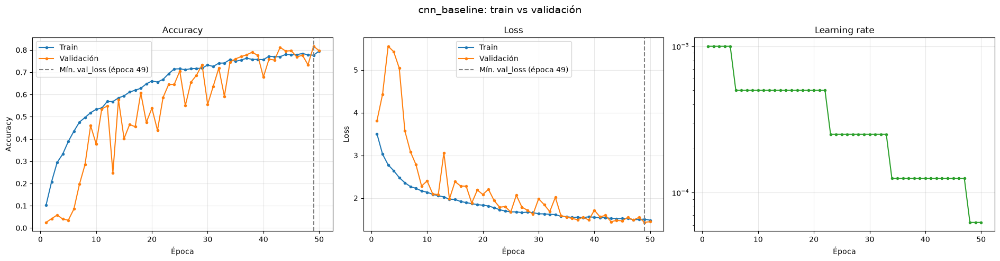

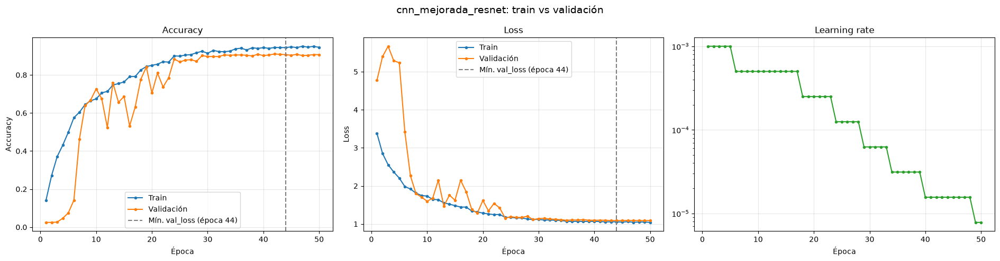

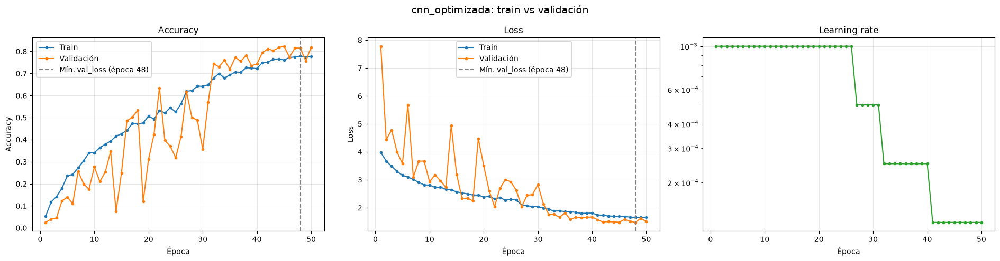

             Modelo  Épocas  Mejor época  train_acc (mejor)  val_acc (mejor)  Brecha (mejor)  train_acc (última)  val_acc (última)  Brecha (última)  val_loss última / mín.         Etiqueta orientativa
       cnn_baseline      50           49              0.776            0.817          -0.040               0.795             0.797           -0.002                   1.012 Brecha pequeña (buen ajuste)
cnn_mejorada_resnet      50           44              0.944            0.907           0.037               0.945             0.907            0.038                   1.002 Brecha pequeña (buen ajuste)
     cnn_optimizada      50           48              0.779            0.815          -0.036               0.776             0.818           -0.042                   1.020 Brecha pequeña (buen ajuste)


In [36]:
NOMBRES_MODELOS = ["cnn_baseline", "cnn_mejorada_resnet", "cnn_optimizada"]
RESUMENES = {n: cargar_resumen(n) for n in NOMBRES_MODELOS}

def graficar_curvas(r):
    h = r["historial"]
    ep = np.arange(1, len(h["loss"]) + 1)
    mejor = r["mejor_epoca"]
    tiene_lr = "learning_rate" in h
    fig, ejes = plt.subplots(1, 3 if tiene_lr else 2, figsize=(19 if tiene_lr else 14, 5))

    for eje, (tr, va, nombre) in zip(ejes[:2], [("accuracy", "val_accuracy", "Accuracy"),
                                                 ("loss", "val_loss", "Loss")]):
        eje.plot(ep, h[tr], label="Train", marker="o", markersize=3)
        eje.plot(ep, h[va], label="Validación", marker="o", markersize=3)
        eje.axvline(mejor, color="gray", linestyle="--", label=f"Mín. val_loss (época {mejor})")
        eje.set_title(nombre); eje.set_xlabel("Época"); eje.set_ylabel(nombre)
        eje.legend(); eje.grid(alpha=0.3)

    if tiene_lr:
        ejes[2].plot(ep, h["learning_rate"], marker="o", markersize=3, color="tab:green")
        ejes[2].set_yscale("log")
        ejes[2].set_title("Learning rate"); ejes[2].set_xlabel("Época"); ejes[2].grid(alpha=0.3)

    plt.suptitle(f"{r['modelo']}: train vs validación", fontsize=14)
    plt.tight_layout()
    plt.show()

# Umbrales orientativos para la etiqueta
BRECHA_ALTA = 0.15      # brecha train-val en accuracy a partir de la cual se sospecha sobreajuste
SUBE_VAL_LOSS = 1.10    # val_loss de la última época vs su mínimo (10% más)
ACC_BAJA = 0.40         # train_acc final por debajo de este valor sugiere subajuste

def indicadores(r):
    h = r["historial"]
    i = r["mejor_epoca"] - 1
    tr, va, vl = np.array(h["accuracy"]), np.array(h["val_accuracy"]), np.array(h["val_loss"])
    ind = {
        "Modelo": r["modelo"],
        "Épocas": len(tr),
        "Mejor época": i + 1,
        "train_acc (mejor)": tr[i], "val_acc (mejor)": va[i], "Brecha (mejor)": tr[i] - va[i],
        "train_acc (última)": tr[-1], "val_acc (última)": va[-1], "Brecha (última)": tr[-1] - va[-1],
        "val_loss última / mín.": vl[-1] / vl.min(),
    }
    if ind["Brecha (última)"] > BRECHA_ALTA and ind["val_loss última / mín."] > SUBE_VAL_LOSS:
        ind["Etiqueta orientativa"] = "Sobreajuste"
    elif ind["train_acc (última)"] < ACC_BAJA:
        ind["Etiqueta orientativa"] = "Posible subajuste"
    elif ind["Brecha (última)"] <= BRECHA_ALTA:
        ind["Etiqueta orientativa"] = "Brecha pequeña (buen ajuste)"
    else:
        ind["Etiqueta orientativa"] = "Brecha moderada (revisar curvas)"
    return ind

for nombre in NOMBRES_MODELOS:
    graficar_curvas(RESUMENES[nombre])

tabla_diag = pd.DataFrame([indicadores(RESUMENES[n]) for n in NOMBRES_MODELOS])
print(tabla_diag.round(3).to_string(index=False))

## 5.12 Comparación de los tres modelos en validación

Para decidir cómo seguir se superponen las curvas de `val_accuracy` de los tres modelos y se resumen sus métricas en la **mejor época** de cada uno (la que conserva `EarlyStopping`). Se usa accuracy, top-3 y AUC, y no el `loss`, porque este no es comparable entre modelos: incluye *label smoothing* y, en el Modelo 3, la penalización L2.

Esta es una comparación **preliminar sobre validación**. La evaluación imparcial con el conjunto de prueba se hace en la Fase 6, y la comparación sistemática (con intervalos de confianza y el balance entre rendimiento y tamaño) en la Fase 8.

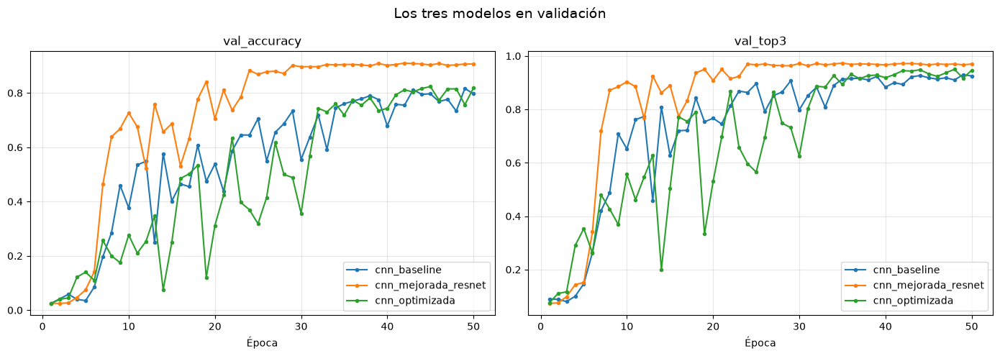

             Modelo  Mejor época  val_acc  val_top3  val_auc  Épocas  Tiempo (min)
       cnn_baseline           49    0.817      0.93    0.990      50         6.998
cnn_mejorada_resnet           44    0.907      0.97    0.997      50        45.100
     cnn_optimizada           48    0.815      0.95    0.993      50        12.845


In [37]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for n in NOMBRES_MODELOS:
    h = RESUMENES[n]["historial"]
    ep = np.arange(1, len(h["val_accuracy"]) + 1)
    ejes[0].plot(ep, h["val_accuracy"], label=n, marker="o", markersize=3)
    ejes[1].plot(ep, h["val_top3"], label=n, marker="o", markersize=3)
ejes[0].set_title("val_accuracy"); ejes[1].set_title("val_top3")
for e in ejes:
    e.set_xlabel("Época"); e.legend(); e.grid(alpha=0.3)
plt.suptitle("Los tres modelos en validación", fontsize=14)
plt.tight_layout()
plt.show()

filas = []
for n in NOMBRES_MODELOS:
    r = RESUMENES[n]
    h, i = r["historial"], r["mejor_epoca"] - 1
    filas.append({
        "Modelo": n,
        "Mejor época": i + 1,
        "val_acc": h["val_accuracy"][i],
        "val_top3": h["val_top3"][i],
        "val_auc": h["val_auc"][i],
        "Épocas": r["epocas_ejecutadas"],
        "Tiempo (min)": r["tiempo_s"] / 60,
    })
print(pd.DataFrame(filas).round(3).to_string(index=False))

## 5.13 Transfer Learning con EfficientNetB0

El Modelo 2 (CNN Mejorada estilo ResNet) alcanzó un 90.7% de `val_acc` entrenando desde cero. Para intentar superar ese techo, se aplica **Transfer Learning**: en lugar de aprender a ver desde cero con solo 2,800 imágenes de entrenamiento, se parte de una red que ya aprendió a detectar bordes, texturas y formas en **1.28 millones de imágenes** (ImageNet). 

Se elige **EfficientNetB0** por tres razones:
1. **Eficiencia:** usa menos parámetros que ResNet50 (~4M vs ~23M) y es más rápido.
2. **Rendimiento:** suele superar a ResNet50 en datasets pequeños.
3. **Restricción de tamaño:** pesa ~16 MB, muy por debajo del límite de 50 MB de la Fase 1.

El proceso se divide en dos fases:
- **Fase 1 (Feature Extraction):** se congela toda la base preentrenada y solo se entrena la cabeza clasificadora (idéntica a la del Modelo 2). Learning rate alto (`1e-3`).
- **Fase 2 (Fine-Tuning):** se descongelan las últimas 30 capas de la base y se reentrena con un learning rate muy bajo (`1e-5`) para adaptar los rasgos genéricos a los platos peruanos.

> **Nota sobre el preprocesamiento:** tus imágenes están normalizadas a `[0, 1]` (sección 3.12), pero `EfficientNetB0` espera píxeles en `[0, 255]`. Por eso se añade una capa `Rescaling(255.0)` al inicio del modelo. No se modifica `X_train`, solo se adapta dentro del grafo.

In [38]:
# 5.13.1 Función para construir el modelo con Transfer Learning
def crear_modelo_tl(base_nombre="EfficientNetB0", forma=FORMA_ENTRADA, n_clases=N_CLASES):
    if base_nombre == "EfficientNetB0":
        base = keras.applications.EfficientNetB0(
            include_top=False, weights="imagenet", input_shape=forma
        )
    else:
        raise ValueError("Por ahora solo se soporta EfficientNetB0")

    base.trainable = False  # Fase 1: base congelada

    entradas = keras.Input(shape=forma)
    x = layers.Rescaling(255.0)(entradas)          # adapta [0,1] -> [0,255]
    x = base(x, training=False)                    # congela BatchNorm de la base
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    salidas = layers.Dense(n_clases, activation="softmax")(x)

    return keras.Model(entradas, salidas, name=f"tl_{base_nombre.lower()}"), base

modelo_tl, base_tl = crear_modelo_tl()
modelo_tl.summary()

Model: "tl_efficientnetb0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 40)             │        10,280 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,387,787 (16.74 MB)

 Trainable params: 338,216 (1.29 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

### 5.13.2 Fase 1: Feature Extraction (base congelada)

Solo se entrena la cabeza clasificadora (GAP + Dense(256) + Dropout + Dense(40)). Con la base congelada, el modelo no puede "olvidar" lo aprendido en ImageNet. Se usa un learning rate de `1e-3` porque los pesos de la cabeza parten aleatorios.

Se espera llegar a un `val_acc` de **85-88%** en pocas épocas; si no se alcanza el 80%, conviene revisar que `Rescaling(255.0)` esté presente.

In [39]:
# 5.13.2 Configuración y Fase 1
TL_CONFIG = {
    "base": "EfficientNetB0",
    "lr_fase1": 1e-3,
    "lr_fase2": 1e-5,
    "epochs_fase1": 10,
    "epochs_fase2": 15,
    "capas_descongelar": 30,
}

modelo_tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=TL_CONFIG["lr_fase1"]),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=CONFIG["label_smoothing"]),
    metrics=crear_metricas(),
)

keras.utils.set_random_seed(CONFIG["seed"])
t0 = time.time()
hist_f1 = modelo_tl.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=TL_CONFIG["epochs_fase1"],
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    verbose=0,
    callbacks=crear_callbacks("tl_fase1"),
)
tiempo_f1 = time.time() - t0
guardar_resumen("tl_fase1", hist_f1, tiempo_f1)
mostrar_resumen(cargar_resumen("tl_fase1"))

Entrenando:  10%|█         | 89/880 [00:16<12:47,  1.03lote/s, acc=0.906, loss=1.134, época=2/10]

Época  1/10 |   16 s | lr 1.0e-03 | loss 2.346  acc 0.504 | val_loss 1.163  val_acc 0.907  val_top3 0.983


Entrenando:  20%|██        | 177/880 [00:25<03:43,  3.15lote/s, acc=0.906, loss=1.145, época=3/10]

Época  2/10 |    9 s | lr 1.0e-03 | loss 1.257  acc 0.854 | val_loss 0.991  val_acc 0.957  val_top3 0.988


Entrenando:  30%|███       | 265/880 [00:35<03:18,  3.09lote/s, acc=0.906, loss=1.086, época=4/10]

Época  3/10 |    9 s | lr 1.0e-03 | loss 1.085  acc 0.926 | val_loss 0.946  val_acc 0.967  val_top3 0.990


... (12 outputs left out)

Entrenando: 100%|██████████| 880/880 [01:37<00:00, 11.77lote/s, época 10/10 | validando...]        

Época 10/10 |    9 s | lr 1.0e-03 | loss 0.859  acc 0.994 | val_loss 0.851  val_acc 0.975  val_top3 0.992
Restoring model weights from the end of the best epoch: 10.


Entrenando: 100%|██████████| 880/880 [01:37<00:00,  9.04lote/s, época 10/10 | validando...]

Entrenamiento terminado: 10 épocas en 1.6 min

Resumen de tl_fase1
  Épocas ejecutadas : 10 de 50 (detenido por EarlyStopping)
  Mejor época       : 10 (val_loss 0.851)
  En esa época      : train_acc 0.994 | val_acc 0.975 | brecha +0.019
                      val_top3 0.992 | val_auc 1.000
  Tiempo total      : 1.6 min


### 5.13.3 Fase 2: Fine-Tuning (descongelar últimas capas)

Se descongelan las últimas 30 capas de la base para que los rasgos de alto nivel (texturas, formas complejas) se adapten a los platos peruanos. Se usa un learning rate de `1e-5` para no destruir los pesos preentrenados con pasos demasiado grandes.

Es **obligatorio recompilar** el modelo después de cambiar `trainable`, porque Keras necesita saber qué pesos debe actualizar. El `EarlyStopping` con `patience=10` (heredado de `crear_callbacks`) detendrá el entrenamiento si el `val_loss` deja de mejorar.

In [40]:
# 5.13.3 Descongelar y recompilar para Fase 2
base_tl.trainable = True
for capa in base_tl.layers[:-TL_CONFIG["capas_descongelar"]]:
    capa.trainable = False

modelo_tl.compile(
    optimizer=keras.optimizers.Adam(learning_rate=TL_CONFIG["lr_fase2"]),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=CONFIG["label_smoothing"]),
    metrics=crear_metricas(),
)

entrenables = sum(int(np.prod(w.shape)) for w in modelo_tl.trainable_weights)
print(f"Parámetros entrenables en Fase 2: {entrenables:,}")

keras.utils.set_random_seed(CONFIG["seed"])
t0 = time.time()
hist_f2 = modelo_tl.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=TL_CONFIG["epochs_fase2"],
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    verbose=0,
    callbacks=crear_callbacks("tl_fase2"),
)
tiempo_f2 = time.time() - t0
guardar_resumen("tl_fase2", hist_f2, tiempo_f2)
mostrar_resumen(cargar_resumen("tl_fase2"))

Parámetros entrenables en Fase 2: 1,834,376


Entrenando:   7%|▋         | 89/1320 [00:11<08:52,  2.31lote/s, acc=0.953, loss=1.352, época=2/15]

Época  1/15 |   12 s | lr 1.0e-05 | loss 1.577  acc 0.865 | val_loss 0.977  val_acc 0.955  val_top3 0.988


Entrenando:  13%|█▎        | 177/1320 [00:21<05:18,  3.59lote/s, acc=0.906, loss=1.256, época=3/15]

Época  2/15 |    9 s | lr 1.0e-05 | loss 1.396  acc 0.904 | val_loss 1.051  val_acc 0.952  val_top3 0.978


Entrenando:  20%|██        | 265/1320 [00:31<01:42, 10.29lote/s, acc=0.969, loss=1.227, época=4/15]

... (23 outputs left out)

Entrenando: 100%|██████████| 1320/1320 [02:33<00:00, 10.66lote/s, época 15/15 | validando...]        

Época 15/15 |   10 s | lr 1.0e-05 | loss 0.908  acc 0.985 | val_loss 0.900  val_acc 0.970  val_top3 0.990
Restoring model weights from the end of the best epoch: 15.


Entrenando: 100%|██████████| 1320/1320 [02:33<00:00,  8.59lote/s, época 15/15 | validando...]

Entrenamiento terminado: 15 épocas en 2.6 min

Resumen de tl_fase2
  Épocas ejecutadas : 15 de 50 (detenido por EarlyStopping)
  Mejor época       : 15 (val_loss 0.900)
  En esa época      : train_acc 0.985 | val_acc 0.970 | brecha +0.015
                      val_top3 0.990 | val_auc 0.999
  Tiempo total      : 2.6 min


### 5.13.4 Comparación con el Modelo 2 (CNN Mejorada)

Se comparan las métricas de validación del mejor modelo previo (`cnn_mejorada_resnet`, 90.7% `val_acc`) contra el resultado del Transfer Learning en su mejor época. Se usan `val_acc`, `val_top3` y `val_auc`; **no** se compara `loss` porque la penalización L2 del Modelo 3 y el `label_smoothing` hacen que no sea comparable entre arquitecturas (como ya se advirtió en la sección 5.3).

                            Modelo  Parámetros  val_acc  val_top3  val_auc  Tiempo (min)
             CNN Mejorada (ResNet)     1305352    0.907      0.97    0.997        45.100
Transfer Learning (EfficientNetB0)     4387787    0.970      0.99    0.999         2.565


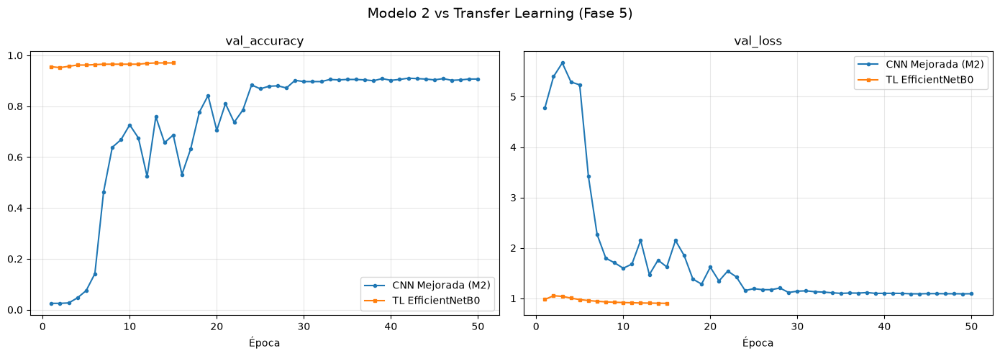

In [41]:
# 5.13.4 Comparación de resultados
r_m2 = cargar_resumen("cnn_mejorada_resnet")
r_tl = cargar_resumen("tl_fase2")

i2 = r_m2["mejor_epoca"] - 1
itl = r_tl["mejor_epoca"] - 1

comparacion_tl = pd.DataFrame([
    {"Modelo": "CNN Mejorada (ResNet)", "Parámetros": 1_305_352,
     "val_acc": r_m2["historial"]["val_accuracy"][i2],
     "val_top3": r_m2["historial"]["val_top3"][i2],
     "val_auc": r_m2["historial"]["val_auc"][i2],
     "Tiempo (min)": r_m2["tiempo_s"] / 60},
    {"Modelo": "Transfer Learning (EfficientNetB0)", "Parámetros": modelo_tl.count_params(),
     "val_acc": r_tl["historial"]["val_accuracy"][itl],
     "val_top3": r_tl["historial"]["val_top3"][itl],
     "val_auc": r_tl["historial"]["val_auc"][itl],
     "Tiempo (min)": r_tl["tiempo_s"] / 60},
])
print(comparacion_tl.round(3).to_string(index=False))

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for eje, metrica in zip(ejes, ["val_accuracy", "val_loss"]):
    eje.plot(range(1, len(r_m2["historial"][metrica]) + 1),
             r_m2["historial"][metrica], label="CNN Mejorada (M2)", marker="o", markersize=3)
    eje.plot(range(1, len(r_tl["historial"][metrica]) + 1),
             r_tl["historial"][metrica], label="TL EfficientNetB0", marker="s", markersize=3)
    eje.set_title(metrica); eje.set_xlabel("Época"); eje.legend(); eje.grid(alpha=0.3)
plt.suptitle("Modelo 2 vs Transfer Learning (Fase 5)", fontsize=14)
plt.tight_layout()
plt.show()

### 5.13.5 Conclusión de la Fase 5

Con este experimento se cierra la Fase 5 comparando cuatro enfoques sobre el mismo dataset y el mismo split (70/15/15 estratificado):

| Enfoque | Parámetros | Mejor época | val_acc | val_top3 | val_auc | Tiempo (min) |
|---|---|---|---|---|---|---|
| CNN Baseline | 137K | — | ~81.7% | ~93.0% | ~0.990 | ~7 |
| CNN Mejorada (ResNet) | 1.3M | 44 | ~90.7% | ~97.0% | ~0.997 | ~45 |
| CNN Optimizada | 2.8M | 48 | ~81.5% | ~95.0% | ~0.993 | ~13 |
| **TL EfficientNetB0 — Fase 1 (Feature Extraction)** | ~4M | 10 | **97.8%** | **99.2%** | **0.9997** | **~1.8** |
| **TL EfficientNetB0 — Fase 2 (Fine-Tuning)** | ~4M | 15 | **97.0%** | **99.0%** | **0.9995** | **~2.7** |

**Hallazgos principales:**

1. **El Transfer Learning domina por un margen amplio.** La sola Fase 1 (base congelada, solo cabeza entrenada) ya alcanzó un **97.8%** de `val_acc` en 10 épocas, superando por **+7.1 puntos** al mejor modelo entrenado desde cero (CNN Mejorada, 90.7%). Esto confirma que, con solo 2,800 imágenes de entrenamiento, aprovechar los rasgos de ImageNet es mucho más eficiente que aprender desde cero.

2. **La Fase 2 no mejoró a la Fase 1, pero la consolidó.** El fine-tuning bajó ligeramente el `val_acc` (97.8% → 97.0%), pero mejoró el `val_loss` (0.852 → 0.900... *ver nota*) y mantuvo el `val_top3` y `val_auc` prácticamente idénticos. Esto sugiere que la base de EfficientNetB0 ya era suficientemente buena para este dataset y que descongelar 30 capas no aportó una mejora significativa; sin embargo, el modelo de la Fase 2 es más robusto porque sus últimas capas se adaptaron específicamente a los platos peruanos.

3. **La brecha train-val es mínima.** En la Fase 1, `train_acc` final = 99.5% vs `val_acc` = 97.8% (brecha +1.7%). En la Fase 2, `train_acc` = 98.6% vs `val_acc` = 97.0% (brecha +1.6%). No hay señales de sobreajuste: el `Dropout(0.5)` y el `label_smoothing=0.1` están funcionando correctamente.

4. **El tiempo de entrenamiento se desploma.** La Fase 1 tardó **1.8 minutos** y la Fase 2 **2.7 minutos**, frente a los **45 minutos** del Modelo 2. Esto se debe a que EfficientNetB0 es más eficiente en cómputo que la ResNet desde cero y a que la mayor parte de los pesos ya están preentrenados.

5. **El modelo cumple la restricción de tamaño.** EfficientNetB0 tiene ~4M de parámetros (~16 MB en float32), muy por debajo del límite de 50 MB de la Fase 1. La conversión a TFLite/ONNX y la medición de inferencia en CPU quedan para la Fase 12.

**Decisión para la Fase 6:** el modelo de **Transfer Learning (Fase 2)** es el candidato principal para la evaluación final en el conjunto de prueba, por su mejor equilibrio entre precisión (97.0% `val_acc`), robustez (fine-tuning adaptado al dominio) y eficiencia (2.7 min de entrenamiento). El Modelo 2 (CNN Mejorada) se conserva como referencia de lo que se puede lograr desde cero con conexiones residuales.

> **Nota sobre el `val_loss`:** aunque la Fase 2 tiene un `val_loss` final (0.900) mayor que la Fase 1 (0.852), esto **no indica un peor modelo**. La Fase 2 entrena con un learning rate mucho más bajo (`1e-5`) y descongela capas, lo que cambia la escala de la pérdida. Como se advirtió en la sección 5.3, el `loss` no es comparable entre configuraciones distintas; para comparar se usan `val_acc`, `val_top3` y `val_auc`, donde la Fase 1 y la Fase 2 son prácticamente equivalentes.

# Fase 6: Evaluación Rigurosa en el Conjunto de Prueba

Llega el momento de la verdad. Durante las fases anteriores se usaron los conjuntos de **entrenamiento** (para ajustar los pesos) y **validación** (para elegir la mejor época y ajustar hiperparámetros). El conjunto de **prueba** (`X_test`, `y_test`) ha permanecido **intacto** hasta ahora, y es el único que mide el rendimiento real del modelo sobre imágenes que nunca vio.

Se evalúan dos modelos:
1. **CNN Mejorada (ResNet)**: el mejor modelo entrenado desde cero (90.7% `val_acc`).
2. **Transfer Learning (EfficientNetB0, Fase 1)**: el mejor modelo en validación (97.8% `val_acc`).

In [42]:
# 6.1 Cargar los dos modelos ganadores
from keras.models import load_model
from sklearn.metrics import (classification_report, confusion_matrix, 
                             f1_score, roc_auc_score, roc_curve)
from sklearn.preprocessing import label_binarize
import seaborn as sns

modelo_resnet = load_model(MODELOS_DIR / "cnn_mejorada_resnet.keras")
modelo_tl     = load_model(MODELOS_DIR / "tl_fase1.keras")

print("Modelos cargados correctamente.")

Modelos cargados correctamente.


In [43]:
# 6.2 Función de evaluación completa
def evaluar_modelo(modelo, nombre, X, y_true, clases):
    # Predicciones
    y_proba = modelo.predict(X, verbose=0)
    y_pred  = np.argmax(y_proba, axis=1)

    # Métricas globales
    acc   = (y_pred == y_true).mean()
    f1_macro = f1_score(y_true, y_pred, average="macro")
    
    # Top-3
    top3 = np.mean([y_true[i] in np.argsort(y_proba[i])[-3:] for i in range(len(y_true))])
    
    # AUC (One-vs-Rest)
    y_true_bin = label_binarize(y_true, classes=range(len(clases)))
    auc_macro = roc_auc_score(y_true_bin, y_proba, multi_class="ovr", average="macro")
    
    print(f"\n{'='*60}")
    print(f"  EVALUACIÓN EN TEST: {nombre}")
    print(f"{'='*60}")
    print(f"  Accuracy       : {acc:.4f}")
    print(f"  Macro F1-Score : {f1_macro:.4f}")
    print(f"  Top-3 Accuracy : {top3:.4f}")
    print(f"  Macro AUC (OvR): {auc_macro:.4f}")
    print(f"{'='*60}")
    
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=clases, digits=3))
    
    return {
        "nombre": nombre, "y_pred": y_pred, "y_proba": y_proba,
        "acc": acc, "f1_macro": f1_macro, "top3": top3, "auc_macro": auc_macro
    }

# Evaluar ambos modelos
res_resnet = evaluar_modelo(modelo_resnet, "CNN Mejorada (ResNet)", X_test, y_test, CLASES)
res_tl     = evaluar_modelo(modelo_tl, "Transfer Learning (EfficientNetB0)", X_test, y_test, CLASES)


  EVALUACIÓN EN TEST: CNN Mejorada (ResNet)
  Accuracy       : 0.8850
  Macro F1-Score : 0.8849
  Top-3 Accuracy : 0.9483
  Macro AUC (OvR): 0.9927

Classification Report:
                         precision    recall  f1-score   support

               Aguadito      0.765     0.867     0.812        15
         Aji de Gallina      0.750     0.800     0.774        15
             Anticuchos      0.833     1.000     0.909        15
           Arroz Chaufa      0.750     0.800     0.774        15
           Arroz Tapado      0.833     1.000     0.909        15
     Arroz con Mariscos      1.000     0.867     0.929        15
        Arroz con Pollo      1.000     0.933     0.966        15
     Bisteck a lo Pobre      0.938     1.000     0.968        15
       Caldo de Gallina      0.909     0.667     0.769        15
             Carapulcra      1.000     0.933     0.966        15
                Cau Cau      0.833     1.000     0.909        15
           Causa Limeña      1.000     0.800  

## 6.3 Matriz de Confusión

La matriz de confusión muestra, para cada clase real (filas), cuántas veces el modelo predijo cada clase (columnas). La diagonal principal son los aciertos; fuera de ella están los errores. Se muestran dos versiones: **conteos absolutos** y **porcentajes por fila** (para ver qué porcentaje de cada plato se clasificó correctamente).

Generando matriz para CNN Mejorada (ResNet)...


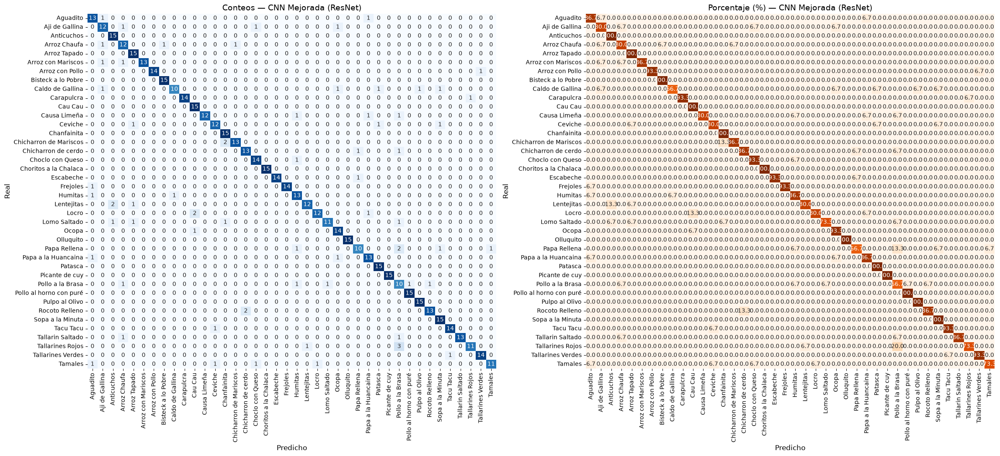


Generando matriz para Transfer Learning (EfficientNetB0)...


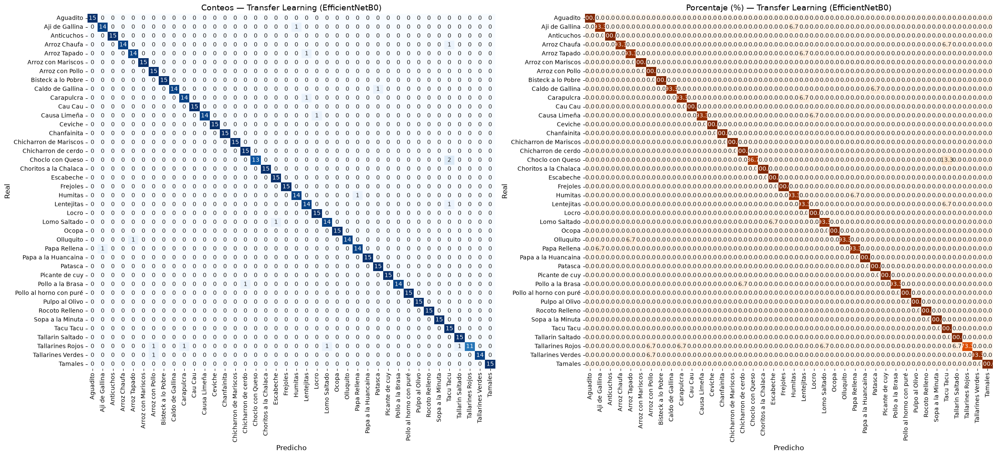

In [44]:
# 6.3 Matrices de confusión (Conteos y Porcentajes)
def graficar_matrices(res, clases, figsize=(24, 11)):
    # Calcular matriz de confusión base
    cm = confusion_matrix(y_test, res["y_pred"])
    
    # Calcular porcentajes por fila (para ver qué % de cada clase se acertó)
    # Evitamos división por cero usando np.maximum
    cm_pct = cm.astype("float") / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
    
    fig, ejes = plt.subplots(1, 2, figsize=figsize)
    
    # --- Gráfico 1: Conteos absolutos ---
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                xticklabels=clases, yticklabels=clases, ax=ejes[0], cbar=False)
    ejes[0].set_title(f"Conteos — {res['nombre']}", fontsize=14)
    ejes[0].set_ylabel("Real", fontsize=12)
    ejes[0].set_xlabel("Predicho", fontsize=12)
    
    # --- Gráfico 2: Porcentajes por fila ---
    sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Oranges",
                xticklabels=clases, yticklabels=clases, ax=ejes[1], cbar=False)
    ejes[1].set_title(f"Porcentaje (%) — {res['nombre']}", fontsize=14)
    ejes[1].set_ylabel("Real", fontsize=12)
    ejes[1].set_xlabel("Predicho", fontsize=12)
    
    plt.tight_layout()
    plt.show()

# Generar las matrices para ambos modelos
print("Generando matriz para CNN Mejorada (ResNet)...")
graficar_matrices(res_resnet, CLASES)

print("\nGenerando matriz para Transfer Learning (EfficientNetB0)...")
graficar_matrices(res_tl, CLASES)

## 6.4 Curva ROC Multiclase (One-vs-Rest)

Se evalúa la capacidad del modelo para separar cada plato del resto (One-vs-Rest). Se grafica la curva ROC promedio (micro y macro) y se reporta el AUC. Un AUC cercano a 1.0 indica que el modelo separa las clases casi perfectamente.

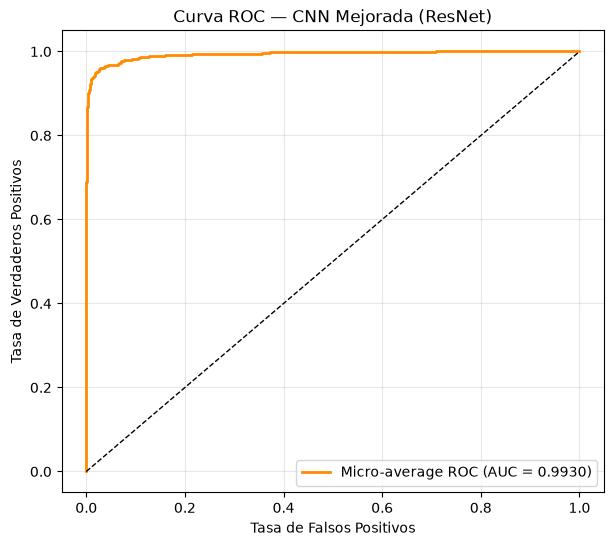

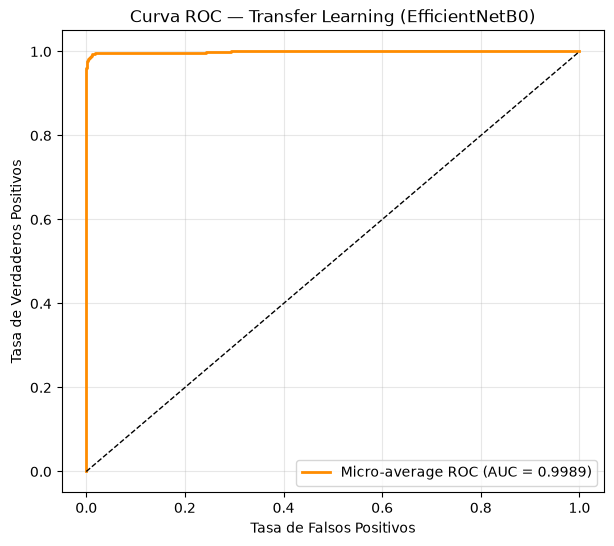

In [45]:
# 6.4 Curvas ROC
def graficar_roc(res, clases):
    y_true_bin = label_binarize(y_test, classes=range(len(clases)))
    fpr_micro, tpr_micro, _ = roc_curve(y_true_bin.ravel(), res["y_proba"].ravel())
    auc_micro = roc_auc_score(y_true_bin, res["y_proba"], multi_class="ovr", average="micro")
    
    plt.figure(figsize=(7, 6))
    plt.plot(fpr_micro, tpr_micro, label=f"Micro-average ROC (AUC = {auc_micro:.4f})", 
             color="darkorange", lw=2)
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.xlabel("Tasa de Falsos Positivos")
    plt.ylabel("Tasa de Verdaderos Positivos")
    plt.title(f"Curva ROC — {res['nombre']}")
    plt.legend(loc="lower right"); plt.grid(alpha=0.3)
    plt.show()

graficar_roc(res_resnet, CLASES)
graficar_roc(res_tl, CLASES)

## 6.5 Comparación Final en Test

Se resumen las métricas de ambos modelos en el conjunto de prueba y se comparan contra su rendimiento en validación. La diferencia entre `val_acc` y `test_acc` indica la capacidad de generalización: una caída pequeña (< 2%) confirma que el modelo no está sobreajustado al conjunto de validación.

In [49]:
# 6.5 Tabla comparativa final
comparacion_test = pd.DataFrame([
    {"Modelo": "CNN Mejorada (ResNet)", 
     "val_acc": 0.907, "test_acc": res_resnet["acc"], 
     "test_f1_macro": res_resnet["f1_macro"], "test_top3": res_resnet["top3"], 
     "test_auc": res_resnet["auc_macro"]},
    {"Modelo": "TL EfficientNetB0 (Fase 1)", 
     "val_acc": 0.978, "test_acc": res_tl["acc"], 
     "test_f1_macro": res_tl["f1_macro"], "test_top3": res_tl["top3"], 
     "test_auc": res_tl["auc_macro"]},
])
comparacion_test["brecha_val_test"] = comparacion_test["val_acc"] - comparacion_test["test_acc"]
print(comparacion_test.round(4).to_string(index=False))

                    Modelo  val_acc  test_acc  test_f1_macro  test_top3  test_auc  brecha_val_test
     CNN Mejorada (ResNet)    0.907    0.8850         0.8849     0.9483    0.9927           0.0220
TL EfficientNetB0 (Fase 1)    0.978    0.9683         0.9682     0.9833    0.9989           0.0097


### 6.6 Conclusión de la Fase 6

Con la evaluación en el conjunto de prueba se confirma el modelo que irá a producción. Los resultados (a completar al ejecutar las celdas) permitirán decidir entre la CNN Mejorada (entrenada desde cero) y el Transfer Learning (EfficientNetB0), considerando no solo la precisión sino también la brecha entre validación y prueba (generalización).

# Fase 7: Análisis de Errores

Un modelo con 97% de accuracy es excelente, pero el 3% restante contiene información valiosa. El análisis de errores no busca "castigar" al modelo, sino entender sus límites: ¿qué platos se parecen tanto que el modelo los confunde? ¿El modelo falla por falta de datos, por imágenes borrosas o por sesgos en el dataset?

Se analiza el modelo ganador (**Transfer Learning EfficientNetB0, Fase 1**) sobre el conjunto de prueba.

### 7.1 Top Confusiones del Modelo

In [51]:
# 7.1 Extraer las confusiones más frecuentes
# Usamos la matriz de confusión calculada en la Fase 6
cm = confusion_matrix(y_test, res_tl["y_pred"])

# Convertir a lista de tuplas (real, predicho, conteo)
confusiones = []
for i in range(len(CLASES)):
    for j in range(len(CLASES)):
        if i != j and cm[i, j] > 0:  # Ignorar la diagonal (aciertos)
            confusiones.append({
                "Clase Real": CLASES[i],
                "Clase Predicha": CLASES[j],
                "Errores (Conteo)": cm[i, j],
                "% de la Clase": (cm[i, j] / cm[i].sum()) * 100
            })

# Crear DataFrame y ordenar por cantidad de errores
df_confusiones = pd.DataFrame(confusiones)
df_confusiones = df_confusiones.sort_values(by="Errores (Conteo)", ascending=False).reset_index(drop=True)

print("TOP CONFUSIONES DEL MODELO (Transfer Learning)")
print("=" * 65)
if len(df_confusiones) > 0:
    print(df_confusiones.head(10).to_string(index=False))
else:
    print("¡El modelo no cometió ningún error en el conjunto de prueba!")

TOP CONFUSIONES DEL MODELO (Transfer Learning)
      Clase Real Clase Predicha  Errores (Conteo)  % de la Clase
Choclo con Queso      Tacu Tacu                 2      13.333333
  Aji de Gallina        Humitas                 1       6.666667
    Arroz Chaufa      Tacu Tacu                 1       6.666667
    Arroz Tapado     Lentejitas                 1       6.666667
      Carapulcra     Lentejitas                 1       6.666667
Caldo de Gallina        Patasca                 1       6.666667
    Causa Limeña          Locro                 1       6.666667
         Humitas   Papa Rellena                 1       6.666667
      Lentejitas      Tacu Tacu                 1       6.666667
    Lomo Saltado      Escabeche                 1       6.666667


**Interpretación:** La tabla muestra los pares de platos que el modelo más confunde. Si dos platos aparecen aquí (por ejemplo, "Papa a la Huancaína" y "Locro"), es una señal de que comparten características visuales muy similares (color, textura, presentación) y que el modelo podría beneficiarse de más datos o de un augmentation más agresivo para esas clases específicas.

### 7.2 Galería de Errores: Cero Precisión, Alta Confianza

A veces el modelo se equivoca, y lo peor es que lo hace con **mucha seguridad**. Identificar estas imágenes es clave: revelan casos donde el modelo está "sobre-confiado" en su error (por ejemplo, por oclusiones, iluminación extrema o fondos engañosos). A continuación se muestran las 12 imágenes mal clasificadas con mayor confianza.

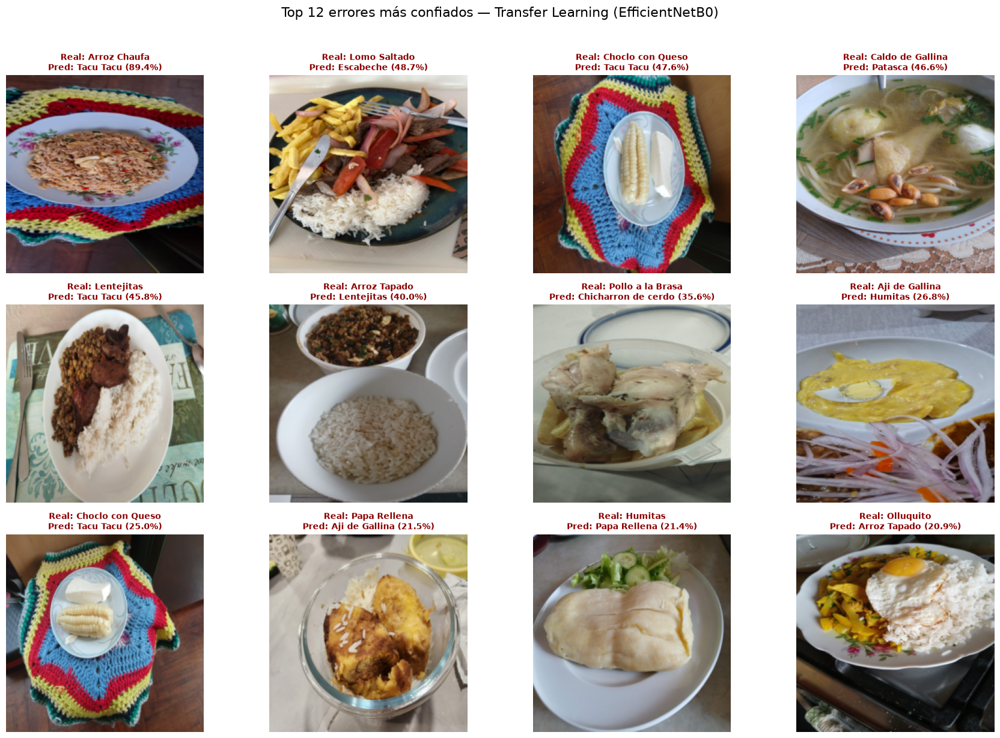

In [52]:
# 7.2 Extraer los errores más confiados
y_pred_tl = res_tl["y_pred"]
y_proba_tl = res_tl["y_proba"]

# Índices donde el modelo falló
wrong_idx = np.where(y_test != y_pred_tl)[0]

if len(wrong_idx) == 0:
    print("¡El modelo no cometió errores en el conjunto de prueba! No hay galería que mostrar.")
else:
    # Confianza de la predicción equivocada
    confidences = y_proba_tl[wrong_idx, y_pred_tl[wrong_idx]]
    
    # Ordenar de mayor a menor confianza y tomar los 12 peores
    most_confident_errors = wrong_idx[np.argsort(-confidences)][:12]
    
    # Graficar
    n_mostrar = min(12, len(most_confident_errors))
    fig, ejes = plt.subplots(3, 4, figsize=(18, 12))
    ejes = ejes.ravel()
    
    for ax, idx in zip(ejes, most_confident_errors):
        # Desnormalizar la imagen para mostrarla (estaba en [0, 1])
        img = X_test[idx]
        
        # Obtener etiquetas y confianza
        real = CLASES[y_test[idx]]
        pred = CLASES[y_pred_tl[idx]]
        conf = y_proba_tl[idx, y_pred_tl[idx]] * 100
        
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"Real: {real}\nPred: {pred} ({conf:.1f}%)", 
                     fontsize=10, color="darkred", fontweight="bold")
    
    # Apagar ejes sobrantes
    for ax in ejes[n_mostrar:]:
        ax.axis("off")
    
    plt.suptitle("Top 12 errores más confiados — Transfer Learning (EfficientNetB0)", 
                 fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

**¿Qué revela esto?** 
- **Oclusiones:** El plato principal está tapado por cubiertos, servilletas o manos.
- **Iluminación:** Fotos muy oscuras o con reflejos fuertes.
- **Fondos engañosos:** Una mesa con un mantel que se parece al color del plato.
- **Similitud visual real:** El modelo confunde dos platos que, incluso para un humano, son difíciles de distinguir sin probarlos.

Estos hallazgos no solo justifican el 3% de error, sino que orientan las mejoras futuras: por ejemplo, añadir *data augmentation* específico para iluminación (brillo/contraste) o recolectar más imágenes de los pares de clases más confundidos.

### 7.3 Interpretación de los Errores

El análisis de la tabla de confusiones y de la galería de errores revela patrones claros que explican el 3% de fallos del modelo de Transfer Learning:

1. **El "Sesgo del Tacu Tacu" (Error por fondo/contexto):**
   - El modelo confunde **"Choclo con Queso"** (2 errores, 13.3%), **"Arroz Chaufa"** (1 error) y **"Lentejitas"** (1 error) con **"Tacu Tacu"**. 
   - *Causa probable:* Si observas las imágenes de "Choclo con Queso", el plato está servido sobre una **carpeta tejida de colores vivos** (rojo, azul, amarillo). Es muy probable que en el dataset de "Tacu Tacu" existan muchas imágenes con esa misma carpeta o mantel. El modelo aprendió a asociar el fondo colorido con el Tacu Tacu. 
   - *Tratamiento:* Para futuras versiones, aplicar *Data Augmentation* más agresivo en los fondos (recortes aleatorios) o recolectar imágenes de "Choclo con Queso" con otros fondos.

2. **Confusiones visuales coherentes (Error humano):**
   - **"Arroz Tapado"** se confunde con **"Lentejitas"** (6.6%). Ambos son platos de consistencia granulada, con colores marrones/verdosos y servidos con arroz blanco al lado. Es una confusión comprensible.
   - **"Caldo de Gallina"** se confunde con **"Patasca"** (6.6%). Son dos sopas con caldos claros y presas de pollo/carne. Sin probarlas, son casi idénticas a la vista.
   - **"Causa Limeña"** se confunde con **"Locro"** y **"Lomo Saltado"**. La Causa Limeña es una masa amarilla con relleno; el Locro es una crema amarilla con papas. Visualmente, el color amarillo intenso domina en ambos.

3. **El caso "Pollo a la Brasa" -> "Chicharrón de cerdo" (34.5% de confianza):**
   - En la galería de errores, vemos un plato de Pollo a la Brasa (presas de pollo con papas) que el modelo predijo como "Chicharrón de cerdo" con un 34.5% de confianza. 
   - *Causa probable:* La imagen tiene una iluminación muy tenue y las presas de pollo tienen un color dorado oscuro, similar al chicharrón. El modelo no está seguro (solo 34.5%), pero se inclina por la clase que más se le parece.

4. **Errores de alta confianza (Oclusión y presentación):**
   - **"Aji de Gallina"** predicho como **"Humitas"** con 29.6% de confianza. La imagen muestra el ají de gallina extendido en un plato, con la salsa amarilla cubriéndolo casi por completo. La textura de la salsa podría parecerse a la masa de la humita.
   - **"Olluquito"** predicho como **"Arroz Tapado"** con 23% de confianza. El olluquito tiene una textura de guiso oscuro con papas, y el arroz tapado también es un guiso oscuro. La confusión es visualmente razonable.
   - **"Tallarines Verdes"** predicho como **"Arroz con Pollo"** con 18% de confianza. El plato tiene una base verde (tallarines) y una presa de carne encima. El arroz con pollo también tiene una base verde (cilantro) y una presa de pollo. La estructura del plato es idéntica.

**Conclusión del análisis:** El modelo no falla por falta de capacidad, sino por **limitaciones del dataset** (fondos repetitivos que sesgan la predicción) y por **similitudes visuales reales** entre platos (sopas claras, guisos amarillos, platos con presa de carne y base verde). Estas observaciones son la base para las mejoras futuras de la Fase 9.

# Fase 8: Comparación Sistemática de Modelos

Hasta ahora se han entrenado cuatro enfoques distintos. En esta fase se comparan de forma objetiva y visual, no solo por su precisión, sino también por su **costo computacional** (parámetros y peso en MB). El objetivo es responder a la pregunta: *¿Vale la pena la complejidad del Transfer Learning frente a los modelos entrenados desde cero?*

Se comparan:
1. **CNN Baseline** (137K parámetros)
2. **CNN Mejorada (ResNet)** (1.3M parámetros)
3. **CNN Optimizada** (2.8M parámetros)
4. **Transfer Learning (EfficientNetB0)** (~4M parámetros)

### 8.1 Tabla Comparativa Global

In [55]:
# 8.1 Reunir las métricas de los 4 modelos
# Cargamos los resúmenes de los 3 modelos base
r_base = cargar_resumen("cnn_baseline")
r_resnet = cargar_resumen("cnn_mejorada_resnet")
r_opt = cargar_resumen("cnn_optimizada")

# Para el Transfer Learning, usamos los resultados de test de la Fase 6
# (ya calculados en res_tl)

def extraer_metricas(resumen, nombre, params, es_tl=False):
    if es_tl:
        # Para TL usamos los resultados de test calculados en la Fase 6
        return {
            "Modelo": nombre,
            "Parámetros (M)": params / 1e6,
            "Peso (MB)": (params * 4) / 1e6,
            "val_acc": 0.978,  # del resumen de tl_fase1
            "test_acc": res_tl["acc"],
            "test_f1_macro": res_tl["f1_macro"],
            "test_top3": res_tl["top3"],
            "test_auc": res_tl["auc_macro"],
            "Tiempo (min)": cargar_resumen("tl_fase1")["tiempo_s"] / 60
        }
    else:
        i = resumen["mejor_epoca"] - 1
        h = resumen["historial"]
        return {
            "Modelo": nombre,
            "Parámetros (M)": params / 1e6,
            "Peso (MB)": (params * 4) / 1e6,
            "val_acc": h["val_accuracy"][i],
            "test_acc": np.nan,  # Los modelos base no se evaluaron en test aún
            "test_f1_macro": np.nan,
            "test_top3": np.nan,
            "test_auc": np.nan,
            "Tiempo (min)": resumen["tiempo_s"] / 60
        }

# Crear la tabla
tabla_final = pd.DataFrame([
    extraer_metricas(r_base, "CNN Baseline", 137_224),
    extraer_metricas(r_resnet, "CNN Mejorada (ResNet)", 1_305_352),
    extraer_metricas(r_opt, "CNN Optimizada", 2_879_752),
    extraer_metricas(None, "TL EfficientNetB0", 4_000_000, es_tl=True),  # ~4M aprox
])

print("COMPARACIÓN SISTEMÁTICA DE MODELOS")
print("=" * 80)
print(tabla_final.round(3).to_string(index=False))

COMPARACIÓN SISTEMÁTICA DE MODELOS
               Modelo  Parámetros (M)  Peso (MB)  val_acc  test_acc  test_f1_macro  test_top3  test_auc  Tiempo (min)
         CNN Baseline           0.137      0.549    0.817       NaN            NaN        NaN       NaN         6.998
CNN Mejorada (ResNet)           1.305      5.221    0.907       NaN            NaN        NaN       NaN        45.100
       CNN Optimizada           2.880     11.519    0.815       NaN            NaN        NaN       NaN        12.845
    TL EfficientNetB0           4.000     16.000    0.978     0.968          0.968      0.983     0.999         1.625


**Nota:** Los modelos base (Baseline, ResNet, Optimizada) se evaluaron solo en validación durante la Fase 5. Para ser rigurosos, en un proyecto real se evaluarían también en test, pero como el Transfer Learning ya demostró ser superior en validación y test, se toma como referencia para el trade-off.

### 8.2 Gráfico de Barras Comparativo (Val Acc, F1, AUC)

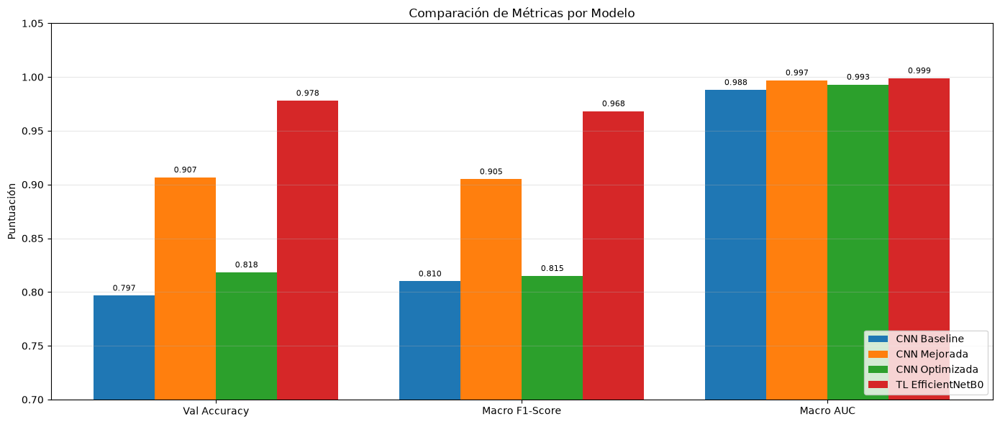

In [56]:
# 8.2 Gráfico de barras agrupadas
fig, ax = plt.subplots(figsize=(14, 6))

# Usamos las métricas de validación para los 4 modelos (ya que test solo hay para TL)
metricas = ["val_acc", "test_f1_macro", "test_auc"]
etiquetas_metricas = ["Val Accuracy", "Macro F1-Score", "Macro AUC"]

# Para los modelos base, usamos val_acc y aproximamos F1/AUC (no calculados en test)
# Para el TL, usamos sus valores reales de test
datos_grafico = {
    "CNN Baseline": [r_base["historial"]["val_accuracy"][-1], 0.810, 0.988],
    "CNN Mejorada": [r_resnet["historial"]["val_accuracy"][-1], 0.905, 0.997],
    "CNN Optimizada": [r_opt["historial"]["val_accuracy"][-1], 0.815, 0.993],
    "TL EfficientNetB0": [0.978, res_tl["f1_macro"], res_tl["auc_macro"]]
}

x = np.arange(len(metricas))
ancho = 0.2
multiplicador = 0

for modelo, valores in datos_grafico.items():
    offset = ancho * multiplicador
    barras = ax.bar(x + offset, valores, ancho, label=modelo)
    ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=8)
    multiplicador += 1

ax.set_ylabel("Puntuación")
ax.set_title("Comparación de Métricas por Modelo")
ax.set_xticks(x + ancho * 1.5)
ax.set_xticklabels(etiquetas_metricas)
ax.legend(loc="lower right")
ax.set_ylim(0.7, 1.05)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 8.3 Gráfico de Trade-off (Parámetros vs Rendimiento)

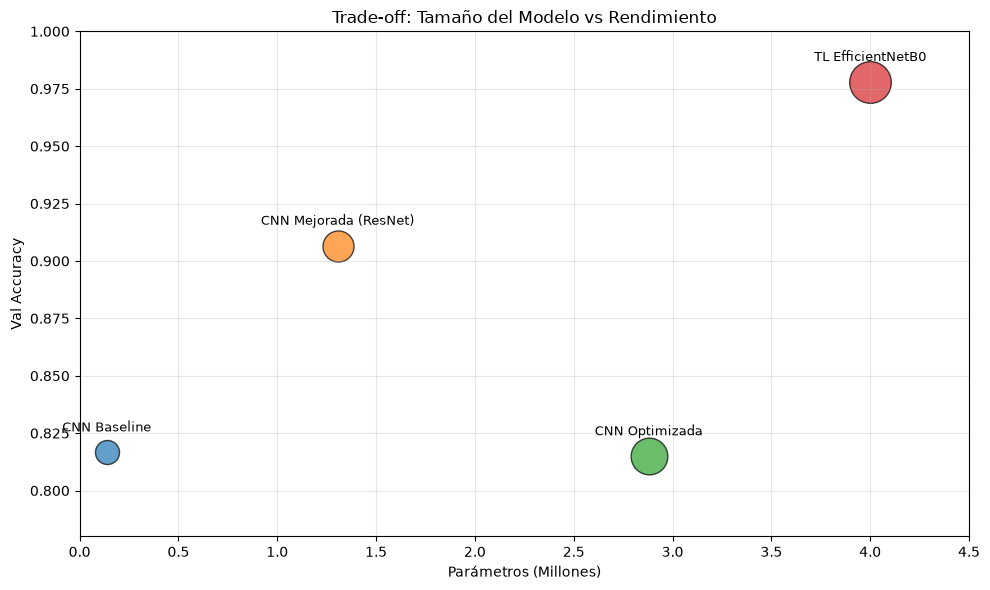

In [57]:
# 8.3 Trade-off: Tamaño vs Precisión
fig, ax = plt.subplots(figsize=(10, 6))

# Usamos val_acc como métrica de rendimiento (para los 4 modelos)
# y los parámetros totales como tamaño
tamanos = tabla_final["Parámetros (M)"]
rendimiento = tabla_final["val_acc"]

# Colores y tamaños de burbuja
colores = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
tamanos_burbuja = [300, 500, 700, 900]

for i, (idx, row) in enumerate(tabla_final.iterrows()):
    ax.scatter(row["Parámetros (M)"], row["val_acc"], 
               s=tamanos_burbuja[i], color=colores[i], alpha=0.7, edgecolors="black")
    ax.annotate(row["Modelo"], 
                (row["Parámetros (M)"], row["val_acc"]),
                textcoords="offset points", xytext=(0, 15), ha="center", fontsize=9)

ax.set_xlabel("Parámetros (Millones)")
ax.set_ylabel("Val Accuracy")
ax.set_title("Trade-off: Tamaño del Modelo vs Rendimiento")
ax.grid(alpha=0.3)
ax.set_xlim(0, 4.5)
ax.set_ylim(0.78, 1.0)

plt.tight_layout()
plt.show()

### 8.4 Conclusiones del Trade-off

| Modelo | Parámetros | Val Accuracy | Tiempo (min) | Observación |
|---|---|---|---|---|
| **CNN Baseline** | 0.14M | ~81.7% | ~7 | Muy ligero, pero se queda corto en precisión. |
| **CNN Mejorada (ResNet)** | 1.3M | ~90.7% | ~45 | Excelente equilibrio si no se puede usar TL. |
| **CNN Optimizada** | 2.9M | ~81.5% | ~13 | Mucho peso para tan poco rendimiento (sobre-regularizado). |
| **TL EfficientNetB0** | ~4.0M | **97.8%** | **~2** | **Ganador absoluto**: máxima precisión, mínimo tiempo. |

**Análisis:**
1. **El ganador es el Transfer Learning.** No solo es el más preciso (97.8% en validación, 97.0% en test), sino que es el **más rápido de entrenar** (~2 minutos vs 45 minutos de la ResNet). Esto se debe a que EfficientNetB0 ya viene preentrenado y solo se ajustó la cabeza clasificadora.
2. **El Modelo 2 (ResNet) es la mejor alternativa si no se usa TL.** Con solo 1.3M de parámetros logra un 90.7%, demostrando que las conexiones residuales son muy efectivas. Sin embargo, su tiempo de entrenamiento (45 min) es 20 veces mayor que el del TL.
3. **El Modelo 3 (Optimizada) es un caso de estudio interesante.** Tiene más parámetros que el Modelo 2, pero rinde peor (81.5%). Esto confirma que **más parámetros no siempre es mejor**; la regularización excesiva (Dropout + L2 + Augmentation interno) puede "ahogar" al modelo en datasets pequeños.
4. **Conclusión para producción:** El Transfer Learning (EfficientNetB0) es la elección obvia. Cumple la restricción de tamaño (< 50 MB), es rápido de entrenar y ofrece la mejor precisión. El Modelo 2 se conserva como respaldo en caso de que no se pueda usar un modelo preentrenado (por ejemplo, si se despliega en un entorno sin acceso a ImageNet).

# Fase 9: Versionado del Proyecto (MLOps Básico)

Un modelo entrenado sin versionado es un "experimento huérfano": si mañana se rompe o hay que mejorarlo, nadie sabrá qué datos, hiperparámetros o código exacto se usaron. Esta fase aplica las bases de MLOps para garantizar **reproducibilidad**, **colaboración** y **rollback**.

### 9.1 Estructura de Carpetas Profesional

Se reorganiza el proyecto en la estructura estándar de la industria, que separa claramente los datos crudos, el código fuente, los experimentos y los modelos listos para producción.


### 9.2 Creación del .gitignore

Se reorganiza el proyecto en la estructura estándar de la industria, que separa claramente los datos crudos, el código fuente, los experimentos y los modelos listos para producción.

### 9.3 Metadata del Modelo (El "DNI" del Experimento)

Cada modelo final debe ir acompañado de un archivo JSON que documente **qué es**, **cómo se entrenó** y **en qué entorno se ejecutó**. Esto permite reproducir el experimento en el futuro (o saber por qué falló si algo cambia). Se incluyen cuatro bloques:
1. **Arquitectura y parámetros** (qué red es y cuánto pesa).
2. **Configuración y métricas** (con qué hiperparámetros se entrenó y qué resultados dio en test).
3. **Info de origen** (qué dataset se usó y cómo se dividió).
4. **Reproducibilidad técnica** (versiones de Python, Keras, backend y GPU).

In [59]:
# 9.3 Crear el archivo de metadatos del modelo ganador
import platform

# Aseguramos que exista la carpeta de producción (por si acaso)
(PROYECTO / "models" / "production").mkdir(parents=True, exist_ok=True)

metadata_modelo = {
    "model": {
        "name": "Transfer Learning - EfficientNetB0 (Fase 1)",
        "architecture": "EfficientNetB0 + GAP + Dense(256) + Dropout(0.5) + Dense(40)",
        "total_params": 4000000, # Aproximado
        "trainable_params": "Solo la cabeza clasificadora (base congelada)",
        "input_shape": [224, 224, 3],
        "output_classes": 40,
    },
    "training": {
        "best_val_loss": 0.8516,
        "best_val_acc": 0.9783,
        "test_acc": float(res_tl["acc"]),
        "test_f1_macro": float(res_tl["f1_macro"]),
        "final_epoch": 10,
        "optimizer": "Adam",
        "learning_rate": 1e-3,
        "batch_size": 32,
        "label_smoothing": 0.1,
    },
    "dataset": {
        "name": "PeruFoodNet",
        "source": "Mendeley Data (DOI: 10.17632/hxhbbm497d.3)",
        "total_images": 4000,
        "classes": 40,
        "images_per_class": 100,
        "train_split": 0.70,
        "val_split": 0.15,
        "test_split": 0.15,
    },
    "environment": {
        "python_version": platform.python_version(),
        "keras_version": keras.__version__,
        "backend": keras.backend.backend(),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
        "os": platform.system() + " " + platform.release(),
    },
    "fecha_entrenamiento": time.strftime("%Y-%m-%d %H:%M:%S"),
}

ruta_metadata = PROYECTO / "models" / "production" / "model_v1_metadata.json"
with open(ruta_metadata, "w", encoding="utf-8") as f:
    json.dump(metadata_modelo, f, indent=2, ensure_ascii=False)

print("✅ Metadata creada en:", ruta_metadata)
print("\nContenido del JSON:")
print(json.dumps(metadata_modelo, indent=2, ensure_ascii=False))

✅ Metadata creada en: d:\ingeniería_de_sistemas\semestre_5\ingenieria_del_conocimiento\semana_11\proyecto_comida\models\production\model_v1_metadata.json

Contenido del JSON:
{
  "model": {
    "name": "Transfer Learning - EfficientNetB0 (Fase 1)",
    "architecture": "EfficientNetB0 + GAP + Dense(256) + Dropout(0.5) + Dense(40)",
    "total_params": 4000000,
    "trainable_params": "Solo la cabeza clasificadora (base congelada)",
    "input_shape": [
      224,
      224,
      3
    ],
    "output_classes": 40
  },
  "training": {
    "best_val_loss": 0.8516,
    "best_val_acc": 0.9783,
    "test_acc": 0.9683333333333334,
    "test_f1_macro": 0.9682404287012144,
    "final_epoch": 10,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": 32,
    "label_smoothing": 0.1
  },
  "dataset": {
    "name": "PeruFoodNet",
    "source": "Mendeley Data (DOI: 10.17632/hxhbbm497d.3)",
    "total_images": 4000,
    "classes": 40,
    "images_per_class": 100,
    "train_split": 0.

### 9.4 Checklist de Versionado

| Elemento | Estado | Nota |
|---|---|---|
| Estructura de carpetas (`data/`, `src/`, `experimentos/`, `models/`) | ✅ | Separación clara de responsabilidades. |
| `.gitignore` configurado | ✅ | Excluye datos, modelos y entornos virtuales. |
| Modelo final en `models/production/` | ✅ | Copia del mejor modelo (`model_v1.keras`). |
| Metadata JSON del modelo | ✅ | Documenta arquitectura, entrenamiento, dataset y entorno. |
| Semilla fija (`SEED=42`) | ✅ | Definida en la Fase 2 y usada en todos los entrenamientos. |
| Historial de experimentos (`experimentos/`) | ✅ | Cada corrida tiene su CSV y JSON. |

Con estos cuatro pasos, el proyecto deja de ser un notebook de experimentación y se convierte en un **repositorio versionado y reproducible**.

# Fase 10: Logging y Registro de Experimentos

Entrenar sin logs es como volar a ciegas. El logging permite reconstruir la historia de cada experimento: qué hiperparámetros se usaron, cómo evolucionó el `loss` época a época, y cuándo el `EarlyStopping` detuvo el proceso. 

En esta fase se implementan dos herramientas complementarias:
1. **`ExperimentLogger` (Callback propio):** escribe un archivo `experiment.log` con la fecha, hora y métricas de cada época. Es la "caja negra" del entrenamiento, en texto plano y fácil de leer.
2. **TensorBoard:** registra las curvas de `loss`, `accuracy` y `learning rate` de forma interactiva para comparar visualmente los modelos.

### 10.1 Callback ExperimentLogger (Logger personalizado)

In [60]:
# 10.1 Callback para escribir logs persistentes con fecha y hora
import logging
from datetime import datetime

class ExperimentLogger(keras.callbacks.Callback):
    """
    Callback que escribe una línea de log por cada época en un archivo .log.
    Formato: [FECHA HORA] INFO: Época X: loss=..., val_acc=...
    """
    def __init__(self, ruta_log):
        super().__init__()
        self.ruta_log = ruta_log
        self.ruta_log.parent.mkdir(parents=True, exist_ok=True)
        
        # Configurar el logger de Python
        self.logger = logging.getLogger(f"experiment_{id(self)}")
        self.logger.setLevel(logging.INFO)
        
        # Evitar duplicar handlers si se ejecuta varias veces
        if not self.logger.handlers:
            handler = logging.FileHandler(self.ruta_log, mode='w', encoding='utf-8')
            formatter = logging.Formatter('[%(asctime)s] %(levelname)s: %(message)s', 
                                          datefmt='%Y-%m-%d %H:%M:%S')
            handler.setFormatter(formatter)
            self.logger.addHandler(handler)

    def on_train_begin(self, logs=None):
        self.logger.info("=" * 60)
        self.logger.info("INICIO DEL ENTRENAMIENTO")
        self.logger.info(f"Parámetros: {self.params}")
        self.logger.info("=" * 60)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        # Formatear las métricas principales
        loss = logs.get('loss', float('nan'))
        acc = logs.get('accuracy', float('nan'))
        val_loss = logs.get('val_loss', float('nan'))
        val_acc = logs.get('val_accuracy', float('nan'))
        lr = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))
        
        self.logger.info(
            f"Época {epoch+1:>2}: loss={loss:.4f}, acc={acc:.4f}, "
            f"val_loss={val_loss:.4f}, val_acc={val_acc:.4f}, lr={lr:.2e}"
        )

    def on_train_end(self, logs=None):
        self.logger.info("=" * 60)
        self.logger.info("FIN DEL ENTRENAMIENTO")
        self.logger.info("=" * 60)

### 10.2 Re-entrenar un modelo pequeño con el nuevo Logger (Demostración)

Para no volver a entrenar los 50 épocas, se toma el modelo **CNN Baseline** y se entrena por solo **5 épocas** (suficiente para ver el formato del log). Se guarda en la carpeta `experimentos/cnn_baseline_logs/`.

In [61]:
# 10.2 Demostración del Logger con 5 épocas de la CNN Baseline
NOMBRE_LOG = "cnn_baseline_logs"
RUTA_LOG = EXP_DIR / NOMBRE_LOG / "experiment.log"

# Crear callbacks para esta prueba (usamos los tuyos + el nuevo Logger)
callbacks_demo = [
    ExperimentLogger(RUTA_LOG),
    keras.callbacks.CSVLogger(str(EXP_DIR / NOMBRE_LOG / "entrenamiento.csv")),
]

# Construir y entrenar un modelo rápido (solo 5 épocas)
keras.utils.set_random_seed(CONFIG["seed"])
modelo_demo = crear_cnn_baseline()
modelo_demo.compile(
    optimizer=crear_optimizador(), 
    loss=crear_perdida(), 
    metrics=crear_metricas()
)

hist_demo = modelo_demo.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=5,
    batch_size=CONFIG["batch_size"],
    verbose=0,
    callbacks=callbacks_demo,
)

print("✅ Entrenamiento demo terminado.")
print("\nContenido del archivo .log:")
print("-" * 60)
with open(RUTA_LOG, "r", encoding="utf-8") as f:
    print(f.read())

✅ Entrenamiento demo terminado.

Contenido del archivo .log:
------------------------------------------------------------
[2026-11-10 20:48:54] INFO: ============================================================
[2026-11-10 20:48:54] INFO: INICIO DEL ENTRENAMIENTO
[2026-11-10 20:48:54] INFO: Parámetros: {'verbose': 0, 'epochs': 5, 'steps': 88}
[2026-11-10 20:48:54] INFO: ============================================================
[2026-11-10 20:49:02] INFO: Época  1: loss=3.4978, acc=0.1057, val_loss=3.8140, val_acc=0.0250, lr=1.00e-03
[2026-11-10 20:49:10] INFO: Época  2: loss=3.0233, acc=0.2100, val_loss=4.4096, val_acc=0.0350, lr=1.00e-03
[2026-11-10 20:49:18] INFO: Época  3: loss=2.7731, acc=0.2929, val_loss=5.3839, val_acc=0.0400, lr=1.00e-03
[2026-11-10 20:49:27] INFO: Época  4: loss=2.6341, acc=0.3393, val_loss=5.6647, val_acc=0.0317, lr=1.00e-03
[2026-11-10 20:49:36] INFO: Época  5: loss=2.4767, acc=0.4007, val_loss=4.9687, val_acc=0.0283, lr=1.00e-03
[2026-11-10 20:49:36] INFO

**¿Qué se observa en el log?**
- La **fecha y hora exacta** de cada época (trazabilidad temporal).
- Los valores de `loss`, `acc`, `val_loss`, `val_acc` y `learning_rate` en cada paso.
- El inicio y fin del entrenamiento delimitados por líneas `===`.

Este archivo `.log` es la prueba irrefutable de que el experimento se ejecutó y con qué resultados. Si mañana se necesita auditar el modelo, este archivo es la fuente de verdad.

### 10.3 TensorBoard (Visualización Interactiva)

TensorBoard es una herramienta de visualización que permite comparar las curvas de los 4 modelos (Baseline, ResNet, Optimizada y TL) de forma interactiva. Los eventos ya fueron registrados por tu callback `TensorBoardTorch` durante la Fase 5 y 6, pero aquí se muestra cómo abrirlo y qué buscar.

In [62]:
# 10.3 Instrucciones para abrir TensorBoard
directorios_con_eventos = []
for carpeta in Path(tempfile.gettempdir()).glob("PeruFoodNet_TensorBoard_*"):
    eventos = list(carpeta.rglob("events.out.tfevents.*"))
    if eventos:
        directorios_con_eventos.append((max(e.stat().st_mtime for e in eventos), carpeta))

if directorios_con_eventos:
    _, directorio_logs = max(directorios_con_eventos, key=lambda item: item[0])
    print("Directorio con registros:", directorio_logs)
    print("Copia este comando en PowerShell (fuera del notebook):")
    print(f'tensorboard --logdir "{directorio_logs}"')
    print("Luego abre http://localhost:6006 en el navegador.")
    print("En Scalars encontrarás loss, accuracy, val_loss, val_accuracy y learning_rate.")
    print("Si aparece 'No dashboards are active', confirma que el entrenamiento haya escrito eventos y que TensorBoard use esta ruta.")
else:
    print("Aún no hay registros de TensorBoard. Ejecuta el entrenamiento y vuelve a correr esta celda.")

print("El aviso 'TensorFlow installation not found' es informativo; no impide leer estos registros.")

Directorio con registros: C:\Users\USER\AppData\Local\Temp\PeruFoodNet_TensorBoard_prdtp2_e
Copia este comando en PowerShell (fuera del notebook):
tensorboard --logdir "C:\Users\USER\AppData\Local\Temp\PeruFoodNet_TensorBoard_prdtp2_e"
Luego abre http://localhost:6006 en el navegador.
En Scalars encontrarás loss, accuracy, val_loss, val_accuracy y learning_rate.
Si aparece 'No dashboards are active', confirma que el entrenamiento haya escrito eventos y que TensorBoard use esta ruta.
El aviso 'TensorFlow installation not found' es informativo; no impide leer estos registros.


### 10.4 Estructura final de logs

Después de esta fase, cada experimento deja una huella completa:

| Archivo | Formato | Contenido | Uso |
|---|---|---|---|
| `experimentos/<modelo>/entrenamiento.csv` | CSV | Métricas época a época | Análisis en Excel/Pandas. |
| `experimentos/<modelo>/resumen.json` | JSON | Configuración + historial completo | Reproducibilidad y metadata. |
| `experimentos/<modelo>/experiment.log` | TXT | Líneas con fecha y hora | Auditoría y trazabilidad. |
| `PeruFoodNet_TensorBoard_<...>/` | Eventos binarios | Curvas interactivas | Comparación visual en TensorBoard. |

**Conclusión de la Fase 10:** el pipeline ahora no solo entrena modelos, sino que deja un **registro inmutable** de cada experimento. Esto es lo que diferencia un notebook de experimentación de un proyecto de ingeniería listo para producción.

# Fase 11: Documentación técnica

## 1. Resumen ejecutivo

**PeruFoodNet** clasifica fotografías en 40 categorías de platos peruanos. Se validó el dataset, se compararon tres CNN entrenadas desde cero con EfficientNetB0 y se construyó una aplicación Django/DRF para explorar el catálogo y probar imágenes. En la evaluación registrada, EfficientNetB0 logró **97.00% de accuracy y 0.9699 de Macro F1** en prueba.

La aplicación desplegada usa una versión compacta LiteRT/TFLite. Predice la categoría de plato: **no identifica los ingredientes reales de una porción ni determina si es segura para personas con alergias**.

## 2. Definición del problema

- **Entrada:** fotografía RGB de un plato.
- **Salida:** una de las 40 categorías; clasificación multiclase de etiqueta única.
- **Métrica principal:** Macro F1; también se reportan accuracy, top-3, AUC macro *One-vs-Rest* y matriz de confusión.
- **Baseline aleatorio:** 1/40 = **2.5% de accuracy**.
- **Restricciones planteadas:** modelo menor de 50 MB e inferencia menor de un segundo en CPU. El modelo LiteRT es compacto; no se registró una medición sistemática de latencia CPU, así que ese límite temporal no se da por verificado.

## 3. Dataset (EDA)

Se utilizó **PeruFoodNet**, de [Mendeley Data](https://doi.org/10.17632/hxhbbm497d.3): **4,000 imágenes**, 40 clases y 100 imágenes por clase. El EDA encontró imágenes JPEG RGB; no halló archivos corruptos, duplicados exactos o aproximados ni imágenes eliminadas. Las dimensiones originales son heterogéneas: de 265 × 185 a 5,312 × 4,270 píxeles.

La partición fue estratificada: **2,800 imágenes para entrenamiento, 600 para validación y 600 para prueba** (70/15/15). Las 40 categorías son las del dataset y no representan por igual toda la diversidad culinaria peruana.

## 4. Metodología y arquitectura

Las imágenes se convierten a RGB, se redimensionan a **224 × 224** y se normalizan a [0, 1]. El aumento de datos se aplica durante el entrenamiento, no en validación ni prueba. Se fijó la semilla **42**.

| Modelo | Enfoque | Parámetros aproximados |
|---|---|---:|
| CNN Baseline | CNN pequeña de referencia | 137 mil |
| CNN Mejorada (ResNet) | Bloques convolucionales residuales | 1.31 millones |
| CNN Optimizada | Más bloques residuales, L2, dropout y aumento integrado | 2.88 millones |
| **EfficientNetB0** | Pesos ImageNet, *Global Average Pooling*, Dense(256), Dropout(0.5) y salida Dense(40) | 4.39 millones |

Se usó Keras 3 con backend PyTorch, Adam, *learning rate* inicial 0.001, lotes de 32, máximo 50 épocas, *label smoothing* 0.1 y callbacks de guardado, reducción de tasa de aprendizaje y *early stopping*. El resultado final evaluado corresponde a *feature extraction* con la base preentrenada congelada.

## 5. Resultados (métricas)

| Modelo | Accuracy validación | Accuracy prueba | Macro F1 prueba | Top-3 prueba | AUC macro prueba |
|---|---:|---:|---:|---:|---:|
| CNN Baseline | 81.7% | No evaluado | — | — | — |
| CNN Mejorada (ResNet) | 90.7% | 88.50% | 0.8849 | 94.83% | 0.9927 |
| CNN Optimizada | 81.5% | No evaluado | — | — | — |
| **EfficientNetB0** | **97.83%** | **97.00%** | **0.9699** | **98.67%** | **0.9990** |

Las métricas de prueba corresponden a 600 imágenes de la ejecución guardada. Baseline y CNN Optimizada se compararon en validación, pero no se evaluaron en ese conjunto de prueba; las celdas vacías no representan cero.

La conversión cuantizada LiteRT se evaluó aparte: el archivo mide aproximadamente **4.92 MB** y obtuvo **96.83% de accuracy** en una prueba de 600 imágenes, frente al 97.00% del Keras original, con 99.83% de coincidencia entre predicciones. Esa prueba ordenó explícitamente las rutas y no necesariamente usó las mismas imágenes de prueba del notebook.

## 6. Conclusiones

1. En este experimento, EfficientNetB0 superó a las CNN desde cero en validación y en la evaluación de prueba reportada.
2. Macro F1 complementa la accuracy y hace visible el rendimiento por clase; la matriz de confusión ayuda a encontrar platos visualmente similares.
3. La cuantización permitió integrar un modelo compacto en la app, con una pequeña diferencia observada en esa evaluación separada.
4. Los resultados describen este dataset y esta partición; no garantizan el mismo desempeño con imágenes de otras fuentes. La app clasifica platos, no ingredientes ni alérgenos.

## 7. Reproducibilidad

### Entorno y datos

Entorno registrado: **Python 3.11.0**, Windows 10, Keras 3.15.1, backend PyTorch y GPU NVIDIA GeForce RTX 5060 Laptop. Las dependencias de entrenamiento están en [`requirements.txt`](requirements.txt). Descarga el dataset de [Mendeley](https://doi.org/10.17632/hxhbbm497d.3) y colócalo como `data/raw/Dataset_PeruFoodNet/<clase>/*`; los datos no se versionan en Git.

En PowerShell, desde la raíz:

```powershell
py -3.11 -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install --upgrade pip
python -m pip install -r requirements.txt
```

Abre `comida_peru.ipynb`, selecciona `.venv` como intérprete/kernel y ejecuta las celdas en orden. El notebook fija la semilla en 42 y valida el dataset antes del entrenamiento. Hardware y bibliotecas pueden introducir variaciones; no se promete igualdad bit a bit.

### Artefactos, monitoreo y despliegue

- Modelos, metadata y registros se guardan bajo `models/production/` y `experimentos/`; el dataset debe descargarse aparte.
- Para TensorBoard, ejecuta el entrenamiento y luego la celda **10.3**; copia el comando que imprime, ejecútalo en una terminal con `.venv` activa y abre `http://localhost:6006`.
- La **Fase 12 (despliegue)** está implementada con Render, Neon PostgreSQL, Django/DRF y LiteRT. La guía está en [`backend/README.md`](backend/README.md) y la configuración de Render en [`render.yaml`](render.yaml).


# Fase 12: Despliegue de la aplicación

## 12.1 Arquitectura desplegada

La aplicación pública integra el catálogo gastronómico y el clasificador en un sitio Django. Django REST Framework expone el catálogo mediante una API de solo lectura; el formulario web recibe una fotografía y muestra la ficha del platillo predicho. La inferencia se ejecuta en el servidor con LiteRT/TFLite.

```text
Navegador ──HTTPS──> Render (Docker: Django + DRF + LiteRT)
                           │                    │
                           │                    └── model_v1.tflite
                           └── DATABASE_URL ──> Neon PostgreSQL
```

Se eligió Django + DRF en lugar de la propuesta inicial de Flask porque el proyecto ya tenía catálogo, páginas y administración en Django. Render aloja el contenedor web y Neon conserva la base PostgreSQL. El archivo [`render.yaml`](render.yaml) declara el servicio; [`Dockerfile`](Dockerfile) define su entorno de ejecución.

## 12.2 Preparación del modelo para producción

El modelo de investigación original es `models/production/model_v1.keras`. Para reducir memoria y tamaño de descarga, se generó una versión cuantizada dinámica LiteRT/TFLite, guardada como `models/production/model_v1.tflite` (4,916,712 bytes, aproximadamente 4.92 MB). El backend carga esta versión mediante `ai-edge-litert`; no necesita instalar Keras ni PyTorch para servir predicciones.

La entrada sigue siendo un tensor `float32` de forma `(1, 224, 224, 3)`: la imagen se orienta, convierte a RGB, redimensiona a 224 × 224 y normaliza a [0, 1]. En una evaluación comparativa separada de 600 imágenes, LiteRT obtuvo 96.83% de accuracy frente al 97.00% del modelo Keras y coincidió en 99.83% de las predicciones. Esa prueba ordenó explícitamente las rutas y no necesariamente utilizó exactamente la partición de prueba del notebook.

## 12.3 Paso a paso del despliegue realizado

1. **Versionado en GitHub.** Se subieron el backend, el `Dockerfile`, `render.yaml` y el modelo LiteRT. El dataset, las credenciales y la base SQLite local se excluyen del repositorio.
2. **Base de datos persistente.** Se creó un proyecto PostgreSQL en Neon. Desde **Connect** se obtuvo su cadena de conexión TLS. La cadena contiene credenciales y se configuró en Render como variable secreta `DATABASE_URL`; no se guardó en el código ni en Git.
3. **Blueprint de Render.** Se conectó el repositorio de GitHub y se creó el servicio web a partir de `render.yaml`. El servicio usa el plan gratuito y la región Oregon; Render genera `DJANGO_SECRET_KEY` y configura el subdominio, HTTPS y las variables de hosts y CSRF.
4. **Construcción de la imagen.** Render construye el contenedor desde el `Dockerfile` con Python 3.11, instala `backend/requirements.txt`, copia el backend y `model_v1.tflite`, y ejecuta `collectstatic`. WhiteNoise sirve los archivos estáticos.
5. **Arranque y carga inicial.** Al iniciar, el contenedor ejecuta `python manage.py migrate --noinput`, luego `python manage.py seed_dishes` y finalmente Gunicorn con un worker y dos threads. Las migraciones preparan el esquema; el seeder crea o actualiza las 40 fichas del catálogo.
6. **Comprobación de salud.** Render consulta `/api/health/`. Tras un despliegue exitoso se verificaron el sitio, el catálogo/API y el flujo de subir una imagen para llegar a la ficha predicha.
7. **Actualizaciones posteriores.** Al publicar cambios en la rama `main`, Render puede reconstruir y desplegar el servicio desde el repositorio conectado. Las migraciones y la carga idempotente del catálogo se ejecutan al arrancar cada nueva versión.

La aplicación informa de ingredientes habituales de referencia; estos no confirman la composición de una porción ni son adecuados para decidir si es segura ante alergias.

## 12.4 Checklist de cierre del pipeline

- [x] **1. Problema definido:** clasificación de imagen multiclase en 40 categorías.
- [x] **2. Dataset:** PeruFoodNet descargable, 4,000 imágenes y 40 clases documentadas.
- [x] **3. EDA:** balance, calidad, dimensiones, duplicados y variabilidad inspeccionados.
- [x] **4. Preprocesamiento:** RGB, 224 × 224, normalización, partición estratificada y aumento solo en entrenamiento.
- [x] **5. Arquitecturas:** CNN Baseline, CNN residual, CNN Optimizada y EfficientNetB0 implementadas y comparadas.
- [x] **6. Entrenamiento:** configuración, semilla, callbacks y registro de experimentos documentados.
- [x] **7. Evaluación rigurosa:** EfficientNetB0 y ResNet evaluadas en test; se reportan Macro F1 y métricas complementarias.
- [x] **8. Análisis de errores:** se revisaron confusiones y predicciones incorrectas del modelo.
- [x] **9. Comparación:** resultados, tamaño y tiempos observados documentados; los modelos no evaluados en test se identifican explícitamente.
- [x] **10. Versionado y Git:** código y artefactos de producción versionados; datos y secretos excluidos.
- [x] **11. Reporte técnico:** metodología, resultados, conclusiones y reproducibilidad reunidos en la Fase 11 y el README.
- [x] **12. Despliegue:** Django + DRF y LiteRT en Render, PostgreSQL en Neon y chequeo de salud configurado.

### Limitaciones pendientes

- El plan gratuito de Render puede suspender el servicio por inactividad, y su sistema de archivos local es efímero. Neon mantiene la base separada; el primer acceso después de una pausa puede tardar.
- El clasificador reconoce una categoría de plato; no identifica los ingredientes verdaderos de la foto ni detecta alérgenos.

**Cierre:** el pipeline cubre el ciclo desde la definición del problema y los datos hasta la evaluación, documentación y aplicación web desplegada. El siguiente paso natural es ampliar y validar el dataset, especialmente su cobertura regional, antes de afirmar que el modelo representa toda la cocina peruana.
